<div style="background:#e8f5e9;border-left:8px solid #2e7d32;padding:12px 18px;font-size:15px;color:#222">
<h2 style="margin:0 0 6px 0">START HERE &mdash; what was changed in this notebook</h2>
<b>Your 18 trained runs are NOT retrained.</b> Every original cell is kept as it was (green = this note, orange = new code, red = a changed line).<br><br>
<b>Run order (about 20 minutes in total, only 2 steps train anything):</b>
<ol>
<li>Run cells <b>0 to 10</b> (they only <i>define</i> functions, instant). <b>Do NOT use "Run all"</b>: the old cell with the endless "hello world" loop would never finish.</li>
<li><b>CHANGE 1</b> &mdash; rebuild the data context from your saved cache (no training, ~1 min).</li>
<li><b>CHANGE 2</b> &mdash; log the hardware and repeat the speed test (no training, ~2 min).</li>
<li><b>CHANGE 3</b> &mdash; audit the leaf-mask on 2,000 images (no training, ~1 min).</li>
<li><b>CHANGE 4</b> &mdash; official-split experiment: ONE short training run (~6 min with EfficientNet-B0, ~2 min with MobileNetV3-Small). This gives the number that measures the leakage.</li>
<li><b>CHANGE 5</b> &mdash; OPTIONAL background-augmentation ablation: one run (~9 min). Skip it if you are short of time.</li>
<li><b>CHANGE 6</b> &mdash; prints one block of numbers. <b>Copy that block and paste it back to Claude.</b></li>
</ol>
<b>If Colab was restarted</b> (the /content folder is empty): run cells 0&ndash;10, then CHANGE 1. It restores your results from Google Drive by itself, but the image cache must be rebuilt once (about 10 minutes, no training). Then continue as above.<br><br><b>CHANGE 0</b> (the only edit to your old code) is in cell 10: it no longer auto-runs <code>main()</code> when the cell is executed.
</div>

In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
plant_disease_research.py  --  one-file experimental pipeline for a conference paper on
"Lightweight, bias-audited and explainable plant-disease classification under simulated field shift".

ONLY dataset used: Kaggle "New Plant Diseases Dataset (Augmented)"  (vipoooool/new-plant-diseases-dataset)
    - found automatically in /kaggle/input, otherwise downloaded with
          kagglehub.dataset_download('vipoooool/new-plant-diseases-dataset')

RUN
    Kaggle (dataset attached) or Colab (kagglehub):   python plant_disease_research.py
    Smoke test (minutes):                              python plant_disease_research.py --quick
    Resume after a crash:                              run the same command again (finished runs are skipped)
    Only 1 seed / fewer models:                        --seeds 0 --models resnet9_se mobilenet_v3_small

WHAT IT DOES (every item below produces tables/figures under  <out_dir>/ )
  A  Leakage audit + group-aware train/val/test split (augmented copies of one photo stay together)
  B  Dataset-bias audit (8-pixel random-forest probe, in the spirit of Noyan 2022)
  C  Models: ResNet-9, ResNet-9+SE (proposed, lightweight), ResNet-18, MobileNetV3-S, EfficientNet-B0
  D  Background-robust augmentation (BG-aug: leaf mask -> random background compositing)
  E  Simulated field shift: textured backgrounds, cast shadows, gamma, strong pose change, blur, noise.
     The shift generator is DIFFERENT from the BG-aug generator, so BG-aug is never tested on its own training distribution.
  F  Bias/robustness probes (leaf-only, background-only, random background, field-sim, blur, dark, noise)
  G  Explainability: Grad-CAM + deletion/insertion AUC + foreground-attribution ratio (+ optional LIME)
  H  Reliability: ECE, temperature scaling, selective accuracy, clean-vs-shifted detection (AUROC)
  I  Efficiency: parameters, GFLOPs, size, CPU/GPU latency, TorchScript/ONNX export
  J  Statistics: mean +- std over seeds, McNemar tests, bootstrap CIs; REPORT.md with all tables
  K  Informal sanity check on the dataset's own 33-image "test" folder (8 classes)
"""

'\nplant_disease_research.py  --  one-file experimental pipeline for a conference paper on\n"Lightweight, bias-audited and explainable plant-disease classification under simulated field shift".\n\nONLY dataset used: Kaggle "New Plant Diseases Dataset (Augmented)"  (vipoooool/new-plant-diseases-dataset)\n    - found automatically in /kaggle/input, otherwise downloaded with\n          kagglehub.dataset_download(\'vipoooool/new-plant-diseases-dataset\')\n\nRUN\n    Kaggle (dataset attached) or Colab (kagglehub):   python plant_disease_research.py\n    Smoke test (minutes):                              python plant_disease_research.py --quick\n    Resume after a crash:                              run the same command again (finished runs are skipped)\n    Only 1 seed / fewer models:                        --seeds 0 --models resnet9_se mobilenet_v3_small\n\nWHAT IT DOES (every item below produces tables/figures under  <out_dir>/ )\n  A  Leakage audit + group-aware train/val/test split (aug

In [2]:
import argparse
import hashlib
import json
import math
import os
import random
import re
import subprocess
import sys
import time
import traceback
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image

import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, matthews_corrcoef, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold

try:
    from scipy.stats import binomtest
except Exception:  # pragma: no cover
    binomtest = None

warnings.filterwarnings("ignore", message=".*lr_scheduler.*")
warnings.filterwarnings("ignore", message=".*least populated class.*")

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
KAGGLE_SLUG = "vipoooool/new-plant-diseases-dataset"

# file-name prefix of the dataset's own 33-image test folder -> class name
OFFICIAL_TEST_MAP = {
    "AppleCedarRust": "Apple___Cedar_apple_rust", "AppleScab": "Apple___Apple_scab",
    "CornCommonRust": "Corn_(maize)___Common_rust_", "PotatoEarlyBlight": "Potato___Early_blight",
    "PotatoHealthy": "Potato___healthy", "TomatoEarlyBlight": "Tomato___Early_blight",
    "TomatoHealthy": "Tomato___healthy", "TomatoYellowCurlVirus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
}

MODEL_LABEL = {"resnet9": "ResNet-9", "resnet9_se": "ResNet-9+SE", "resnet18": "ResNet-18",
               "mobilenet_v3_small": "MobileNetV3-S", "efficientnet_b0": "EfficientNet-B0"}
TV_MODELS = {"resnet18", "mobilenet_v3_small", "efficientnet_b0"}
PROBE_CONDS = ["clean", "leaf_on_gray", "leaf_on_random_bg", "bg_only", "field_sim", "blur", "dark", "noise"]

In [3]:
# =====================================================================================
# 0. small utilities
# =====================================================================================
def log(*a):
    print(*a, flush=True)


def odd(k):
    k = max(3, int(k))
    return k if k % 2 == 1 else k + 1


def seed_everything(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


def _jsonable(o):
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def jdump(obj, path):
    with open(path, "w", encoding="utf8") as f:
        json.dump(obj, f, indent=2, default=_jsonable)


def safe(fn, *a, **k):
    """Run a reporting step; a failure in a figure must never kill a multi-hour experiment."""
    try:
        return fn(*a, **k)
    except Exception as e:  # noqa
        log(f"[warn] {fn.__name__} failed: {type(e).__name__}: {e}")
        traceback.print_exc(limit=3)
        return None


def get_args(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data_root", default=None,
                   help="optional folder containing train/ and valid/. Default: /kaggle/input, else kagglehub download")
    p.add_argument("--out_dir", default=None)
    p.add_argument("--cache_dir", default=None)
    p.add_argument("--quick", action="store_true", help="tiny smoke-test configuration")
    p.add_argument("--img_size", type=int, default=None, help="default 128 (64 with --quick)")
    p.add_argument("--epochs", type=int, default=None, help="default 6 (1 with --quick)")
    p.add_argument("--batch_size", type=int, default=None, help="default 128")
    p.add_argument("--seeds", type=int, nargs="+", default=None, help="default 0 1 2")
    p.add_argument("--models", nargs="+", default=None,
                   help="subset of: resnet9 resnet9_se resnet18 mobilenet_v3_small efficientnet_b0")
    p.add_argument("--bg_models", nargs="+", default=None, help="models also trained with BG-aug")
    p.add_argument("--bg_prob", type=float, default=0.5)
    p.add_argument("--width", type=int, default=32, help="ResNet-9 base width (original notebook used 64)")
    p.add_argument("--pretrained", type=int, default=1, help="ImageNet weights for torchvision baselines")
    p.add_argument("--lr", type=float, default=None)
    p.add_argument("--wd", type=float, default=0.01)
    p.add_argument("--max_per_class", type=int, default=None, help="0 = use all images")
    p.add_argument("--xai_n", type=int, default=None, help="images used for Grad-CAM metrics")
    p.add_argument("--split_seed", type=int, default=42)
    p.add_argument("--workers", type=int, default=None, help="threads used to build the image cache")
    p.add_argument("--no_amp", action="store_true")
    p.add_argument("--export", type=int, default=1, help="export TorchScript/ONNX of the proposed model")
    p.add_argument("--lime", action="store_true", help="also make a LIME figure (needs: pip install lime)")
    a, _ = p.parse_known_args(argv)
    q = a.quick
    a.img_size = a.img_size or (64 if q else 128)
    a.epochs = a.epochs or (1 if q else 6)
    a.batch_size = a.batch_size or (64 if q else 128)
    a.seeds = a.seeds if a.seeds is not None else ([0] if q else [0, 1, 2])
    a.models = a.models or (["resnet9_se", "mobilenet_v3_small"] if q
                            else ["resnet9", "resnet9_se", "resnet18", "mobilenet_v3_small", "efficientnet_b0"])
    a.bg_models = a.bg_models if a.bg_models is not None else (["resnet9_se"] if not q else ["resnet9_se"])
    a.max_per_class = a.max_per_class if a.max_per_class is not None else (40 if q else 0)
    a.xai_n = a.xai_n or (32 if q else 200)
    a.workers = a.workers or max(2, os.cpu_count() or 2)
    kaggle = os.path.isdir("/kaggle/working")
    a.out_dir = a.out_dir or ("/kaggle/working/outputs" if kaggle else "outputs")
    a.cache_dir = a.cache_dir or ("/kaggle/temp/plant_cache" if os.path.isdir("/kaggle/temp") else "cache")
    for m in a.models + a.bg_models:
        if m not in MODEL_LABEL:
            raise ValueError(f"unknown model '{m}'. choose from {list(MODEL_LABEL)}")
    return a



In [4]:
# =====================================================================================
# 1. data discovery, leakage audit, group-aware split, uint8 image cache
# =====================================================================================
def _n_class_dirs(p):
    try:
        return sum(1 for e in os.scandir(p) if e.is_dir())
    except OSError:
        return 0


def _scan_for_pv(base):
    """Find the folder that contains both train/ and valid/ (class sub-folders) below `base`."""
    if not base or not os.path.isdir(base):
        return None
    base = os.path.abspath(base)
    d0 = base.count(os.sep)
    for dp, dn, _ in os.walk(base, followlinks=True):          # Kaggle/kagglehub mounts may be symlinks
        if dp.count(os.sep) - d0 >= 4:
            dn[:] = []
            continue
        if "train" in dn and "valid" in dn and _n_class_dirs(os.path.join(dp, "train")) >= 3 \
                and _n_class_dirs(os.path.join(dp, "valid")) >= 3:
            return Path(dp)
    return None


def find_pv_root(user_root=None):
    """--data_root  ->  /kaggle/input  ->  kagglehub.dataset_download('vipoooool/new-plant-diseases-dataset')."""
    if user_root:
        r = _scan_for_pv(user_root)
        if r:
            return r
        raise FileNotFoundError(f"No folder with train/ and valid/ below --data_root '{user_root}'")
    r = _scan_for_pv("/kaggle/input")
    if r:
        return r
    log(f"    dataset not found locally -> kagglehub.dataset_download('{KAGGLE_SLUG}')")
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    try:
        path = kagglehub.dataset_download(KAGGLE_SLUG)
    except Exception as e:  # noqa
        raise RuntimeError(f"kagglehub download failed ({type(e).__name__}: {e}). Turn Internet on, run "
                           f"kagglehub.login() / set KAGGLE_USERNAME + KAGGLE_KEY, or attach the dataset "
                           f"to the notebook and/or pass --data_root.") from e
    r = _scan_for_pv(path)
    if r:
        return r
    raise FileNotFoundError(f"Downloaded '{KAGGLE_SLUG}' to {path} but found no train/ and valid/ folders")


_AUG_SUFFIX = re.compile(r"(?:_(?:flip(?:lr|tb)|\d{2,3}deg|new[a-z]*|rot\d*))+$", re.I)


def group_key(cls, fname):
    """Augmented copies (…_flipTB, …_90deg, …) of one source photo share a group."""
    stem = os.path.splitext(fname)[0].lower().strip()
    return f"{cls}|{_AUG_SUFFIX.sub('', stem)}", stem


def index_pv(root):
    rows, classes = [], None
    for split in ("train", "valid"):
        sd = Path(root) / split
        cl = sorted(d.name for d in os.scandir(sd) if d.is_dir())
        if classes is None:
            classes = cl
        elif cl != classes:
            raise ValueError("train/ and valid/ have different class folders")
        for ci, c in enumerate(cl):
            for fn in sorted(os.listdir(sd / c)):
                if os.path.splitext(fn)[1].lower() in IMG_EXT:
                    g, stem = group_key(c, fn)
                    rows.append((str(sd / c / fn), ci, c, split, fn, g, stem))
    df = pd.DataFrame(rows, columns=["path", "label", "cls", "official", "fname", "group", "stem"])
    return df, classes


def audit_leakage(df, out_dir):
    base_of = df.group.str.split("|", n=1).str[1]
    n_suffix = int((base_of != df.stem).sum())
    tr = set(df.group[df.official == "train"])
    va = set(df.group[df.official == "valid"])
    shared = tr & va
    n_valid = int((df.official == "valid").sum())
    leaked = int(df.group[df.official == "valid"].isin(shared).sum())
    audit = dict(n_images=len(df), n_groups=int(df.group.nunique()), files_with_aug_suffix=n_suffix,
                 official_train_groups=len(tr), official_valid_groups=len(va), shared_groups=len(shared),
                 valid_images_whose_group_is_in_train=leaked,
                 valid_leak_fraction=leaked / max(1, n_valid))
    log("\n[A] LEAKAGE AUDIT (official train/valid split)")
    for k, v in audit.items():
        log(f"    {k:42s}: {v}")
    if n_suffix == 0:
        log("    [note] no augmentation suffix (_flipTB/_90deg/...) was detected in file names, so every image\n"
            "           is its own group. Inspect the sample names below; if they carry another suffix pattern,\n"
            "           extend _AUG_SUFFIX so that augmented copies are grouped with their source photo.")
        for fn in df.fname.sample(min(5, len(df)), random_state=0):
            log(f"           e.g. {fn}")
    jdump(audit, Path(out_dir) / "audit_leakage.json")
    return audit


def make_split(df, seed=42):
    y = df.label.values
    g = pd.factorize(df.group)[0]
    X = np.zeros(len(df))
    trv, te = next(StratifiedGroupKFold(7, shuffle=True, random_state=seed).split(X, y, g))
    tr_, va_ = next(StratifiedGroupKFold(6, shuffle=True, random_state=seed).split(X[trv], y[trv], g[trv]))
    tr, va = np.sort(trv[tr_]), np.sort(trv[va_])
    te = np.sort(te)
    G = [set(g[i]) for i in (tr, va, te)]
    assert not (G[0] & G[1]) and not (G[0] & G[2]) and not (G[1] & G[2]), "group leakage between splits!"
    return tr, va, te


def load_rgb(path, S):
    with Image.open(path) as im:
        im.draft("RGB", (S, S))                       # fast JPEG down-scaling at decode time
        im = im.convert("RGB")
        if im.size != (S, S):
            im = im.resize((S, S), Image.BILINEAR)
        return np.asarray(im, dtype=np.uint8)


def build_cache(paths, S, tag, cache_dir, workers):
    """Decode every image once -> uint8 NHWC .npy (memory-mapped). Returns (array, ok_mask)."""
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    key = hashlib.md5(("\n".join(paths) + f"|{S}").encode()).hexdigest()[:10]
    f_arr, f_ok = cache_dir / f"{tag}_{S}_{key}.npy", cache_dir / f"{tag}_{S}_{key}.ok.npy"
    if f_arr.exists() and f_ok.exists():
        log(f"    cache hit: {f_arr.name}")
        return np.load(f_arr, mmap_mode="r"), np.load(f_ok)
    n = len(paths)
    log(f"    building cache {f_arr.name}: {n} images @ {S}px ({n * S * S * 3 / 1e9:.2f} GB) ...")
    tmp = str(f_arr) + ".tmp"
    arr = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(n, S, S, 3))
    ok = np.ones(n, dtype=bool)

    def work(i, out=arr, flags=ok):
        try:
            out[i] = load_rgb(paths[i], S)
        except Exception:  # corrupt file -> excluded later
            flags[i] = False

    t0 = time.time()
    with ThreadPoolExecutor(workers) as ex:
        for k, _ in enumerate(ex.map(work, range(n))):
            if (k + 1) % 20000 == 0:
                log(f"      {k + 1}/{n}  ({time.time() - t0:.0f}s)")
    arr.flush()
    del arr
    os.replace(tmp, f_arr)
    np.save(f_ok, ok)
    if not ok.all():
        log(f"    [warn] {int((~ok).sum())} unreadable images will be skipped")
    log(f"    cache built in {time.time() - t0:.0f}s")
    return np.load(f_arr, mmap_mode="r"), ok


def index_official_test(pv_root, class_to_idx):
    """The dataset's own tiny test folder (33 photos, 8 classes) sits next to the 'Augmented' folder."""
    base = Path(pv_root).parent.parent
    for cand in (base / "test" / "test", base / "test"):
        if not cand.is_dir():
            continue
        rows = []
        for fn in sorted(os.listdir(cand)):
            stem, ext = os.path.splitext(fn)
            if ext.lower() in IMG_EXT:
                cls = OFFICIAL_TEST_MAP.get(re.sub(r"\d+$", "", stem))
                if cls in class_to_idx:
                    rows.append((str(cand / fn), class_to_idx[cls]))
        if rows:
            return pd.DataFrame(rows, columns=["path", "label"])
    return None


# ---- batching straight from the uint8 cache (no DataLoader workers, no per-epoch JPEG decoding) ----
def iterate_batches(arr, y, idx, bs, dev, shuffle=False, seed=0, drop_last=False):
    idx = np.asarray(idx)
    if shuffle:
        idx = np.random.default_rng(seed).permutation(idx)
    n = len(idx)
    stop = n - (n % bs) if drop_last else n
    for i in range(0, stop, bs):
        sel = np.sort(idx[i:i + bs])
        xb = torch.from_numpy(np.ascontiguousarray(arr[sel])).to(dev)
        yb = None if y is None else torch.from_numpy(np.asarray(y[sel], dtype=np.int64)).to(dev)
        yield xb, yb


def to_float(xb):
    """uint8 NHWC -> float32 NCHW in [0,1]."""
    return xb.permute(0, 3, 1, 2).float().div_(255.0)



In [5]:
# =====================================================================================
# 2. leaf mask, background-robust augmentation, probe conditions (all batched on the GPU)
# =====================================================================================
def _dilate(m, k):
    return F.max_pool2d(m, k, 1, k // 2)


def _erode(m, k):
    return 1 - F.max_pool2d(1 - m, k, 1, k // 2)


@torch.no_grad()
def leaf_mask(x, sat_thr=0.18, dist_thr=0.12):
    """Heuristic foreground (leaf) mask for plain-background lab images.
    leaf = saturated pixels  OR  pixels far from the (grey) border colour; closing fills holes, opening removes specks.
    x: (B,3,H,W) in [0,1]  ->  (B,1,H,W) in {0,1}"""
    B, _, H, W = x.shape
    mx, mn = x.amax(1, keepdim=True), x.amin(1, keepdim=True)
    sat = (mx - mn) / (mx + 1e-6)
    bw = max(2, H // 20)
    border = torch.cat([x[:, :, :bw, :].flatten(2), x[:, :, -bw:, :].flatten(2),
                        x[:, :, :, :bw].flatten(2), x[:, :, :, -bw:].flatten(2)], 2)
    bg = border.median(2).values[:, :, None, None]
    bg_sat = (bg.amax(1, keepdim=True) - bg.amin(1, keepdim=True)) / (bg.amax(1, keepdim=True) + 1e-6)
    dist = (x - bg).pow(2).sum(1, keepdim=True).sqrt()
    use_dist = (bg_sat < 0.15).float()               # distance rule only if the border really looks like a grey backdrop
    m = ((sat > sat_thr).float() + use_dist * (dist > dist_thr).float()).clamp(max=1)
    kc, ko = odd(H / 14), odd(H / 40)
    m = _erode(_dilate(m, kc), kc)
    m = _dilate(_erode(m, ko), ko)
    return m


def soft(m):
    k = odd(m.shape[-1] / 25)
    return F.avg_pool2d(m, k, 1, k // 2, count_include_pad=False)


def random_background(x):
    """Random solid colour / low-frequency colour field / blurred clutter taken from other images in the batch."""
    B, _, H, W = x.shape
    d = x.device
    t = torch.randint(0, 3, (B, 1, 1, 1), device=d)
    solid = torch.rand(B, 3, 1, 1, device=d).expand(B, 3, H, W)
    low = F.interpolate(torch.rand(B, 3, 4, 4, device=d), size=(H, W), mode="bicubic", align_corners=False).clamp(0, 1)
    k = odd(H / 6)
    clutter = F.avg_pool2d(x.roll(1, 0).flip(3), k, 1, k // 2, count_include_pad=False)
    bg = torch.where(t == 0, solid, torch.where(t == 1, low, clutter))
    return (bg + 0.03 * torch.randn_like(bg)).clamp(0, 1)


def replace_background(x, p):
    m = soft(leaf_mask(x))
    out = m * x + (1 - m) * random_background(x)
    sel = torch.rand(x.size(0), 1, 1, 1, device=x.device) < p
    return torch.where(sel, out, x)


def random_affine(x, max_rot=20.0, scale=(0.85, 1.15), max_shift=0.08):
    B, d = x.size(0), x.device
    ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(max_rot)
    sc = torch.empty(B, device=d).uniform_(*scale)
    tx = (torch.rand(B, device=d) * 2 - 1) * max_shift * 2
    ty = (torch.rand(B, device=d) * 2 - 1) * max_shift * 2
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


@torch.no_grad()
def gpu_augment(x, bg_prob=0.0):
    """Standard aug (flips, rotation/scale/shift, brightness/contrast) + optional BG replacement."""
    B, d = x.size(0), x.device
    x = torch.where(torch.rand(B, 1, 1, 1, device=d) < 0.5, x.flip(3), x)
    x = torch.where(torch.rand(B, 1, 1, 1, device=d) < 0.5, x.flip(2), x)
    x = random_affine(x)
    if bg_prob > 0:
        x = replace_background(x, bg_prob)
    c = torch.empty(B, 1, 1, 1, device=d).uniform_(0.8, 1.2)
    b = torch.empty(B, 1, 1, 1, device=d).uniform_(0.8, 1.2)
    mu = x.mean((1, 2, 3), keepdim=True)
    return (((x - mu) * c + mu) * b).clamp(0, 1)


def fractal_background(B, H, W, d):
    """Multi-octave value noise tinted soil / grass / straw / stone. Never used during training (held-out generator)."""
    n = torch.zeros(B, 1, H, W, device=d)
    amp, tot = 1.0, 0.0
    for g in (3, 6, 12, 24):
        n = n + amp * F.interpolate(torch.rand(B, 1, g, g, device=d), size=(H, W), mode="bilinear", align_corners=False)
        tot += amp
        amp *= 0.6
    n = n / tot
    pal = torch.tensor([[.35, .25, .15], [.20, .40, .15], [.60, .55, .30], [.45, .45, .50]], device=d)
    col = pal[torch.randint(0, 4, (B,), device=d)].view(B, 3, 1, 1)
    return ((0.4 + 1.2 * n) * col).clamp(0, 1)


@torch.no_grad()
def field_sim(x):
    """Held-out synthetic 'field' shift: natural-colour textured background, cast shadow, gamma, stronger pose change,
    blur and noise. None of these generators is used by BG-aug, so BG-aug is not evaluated on its own training data."""
    B, _, H, W = x.shape
    d = x.device
    m = soft(leaf_mask(x))
    img = m * x + (1 - m) * fractal_background(B, H, W, d)
    yy, xx = torch.meshgrid(torch.linspace(-1, 1, H, device=d), torch.linspace(-1, 1, W, device=d), indexing="ij")
    ang = torch.rand(B, 1, 1, device=d) * 2 * math.pi
    g = xx[None] * torch.cos(ang) + yy[None] * torch.sin(ang) + (torch.rand(B, 1, 1, device=d) - 0.5)
    img = img * (1 - 0.5 * torch.sigmoid(5 * g))[:, None]
    img = img.clamp(1e-4, 1) ** torch.empty(B, 1, 1, 1, device=d).uniform_(0.7, 1.5)
    img = random_affine(img, max_rot=45.0, scale=(0.7, 1.3), max_shift=0.15)
    k = odd(H / 32)
    blurred = F.avg_pool2d(img, k, 1, k // 2, count_include_pad=False)
    img = torch.where(torch.rand(B, 1, 1, 1, device=d) < 0.5, blurred, img)
    return (img + 0.03 * torch.randn_like(img)).clamp(0, 1)


@torch.no_grad()
def apply_condition(x, cond):
    """Evaluation-time probes used for the bias / robustness audit."""
    H = x.shape[-1]
    if cond == "clean":
        return x
    if cond == "blur":
        k = odd(H / 10)
        return F.avg_pool2d(x, k, 1, k // 2, count_include_pad=False)
    if cond == "dark":
        return x * 0.5
    if cond == "noise":
        return (x + 0.08 * torch.randn_like(x)).clamp(0, 1)
    if cond == "field_sim":
        return field_sim(x)
    m = soft(leaf_mask(x))
    if cond == "leaf_on_gray":
        return m * x + (1 - m) * 0.5
    if cond == "leaf_on_random_bg":
        return m * x + (1 - m) * random_background(x)
    if cond == "bg_only":                              # leaf removed, background kept
        return (1 - m) * x + m * 0.5
    raise ValueError(cond)



In [6]:
# =====================================================================================
# 3. models
# =====================================================================================
def conv_bn(cin, cout, pool=False):
    layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
    if pool:
        layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)


class SE(nn.Module):
    def __init__(self, c, r=8):
        super().__init__()
        h = max(c // r, 4)
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, h, 1), nn.ReLU(inplace=True),
                                nn.Conv2d(h, c, 1), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x)


class ResBlock(nn.Module):
    def __init__(self, c, se):
        super().__init__()
        self.body = nn.Sequential(conv_bn(c, c), conv_bn(c, c))
        self.se = SE(c) if se else nn.Identity()

    def forward(self, x):
        return x + self.se(self.body(x))


class ResNet9(nn.Module):
    """ResNet-9 (the notebook's CNN_NeuralNet) made resolution-independent, narrower and optionally SE-augmented."""

    def __init__(self, num_classes, width=32, se=False, drop=0.2):
        super().__init__()
        w = width
        self.stem = conv_bn(3, w)
        self.layer1 = nn.Sequential(conv_bn(w, 2 * w, pool=True), ResBlock(2 * w, se))
        self.layer2 = nn.Sequential(conv_bn(2 * w, 4 * w, pool=True))
        self.layer3 = nn.Sequential(conv_bn(4 * w, 8 * w, pool=True), ResBlock(8 * w, se))
        self.head = nn.Sequential(nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(8 * w, num_classes))

    def forward(self, x):
        return self.head(self.layer3(self.layer2(self.layer1(self.stem(x)))))


class NormWrap(nn.Module):
    """Takes images in [0,1] and applies ImageNet normalisation inside the model."""

    def __init__(self, net):
        super().__init__()
        self.net = net
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        return self.net((x - self.mean) / self.std)


def build_model(name, nc, width=32, pretrained=False):
    """returns (NormWrap(model), pretrained_weights_really_used)"""
    used = False
    if name in ("resnet9", "resnet9_se"):
        net = ResNet9(nc, width, se=name.endswith("_se"))
    else:
        tv = torchvision.models
        fn = {"resnet18": tv.resnet18, "mobilenet_v3_small": tv.mobilenet_v3_small,
              "efficientnet_b0": tv.efficientnet_b0}[name]
        net = None
        if pretrained:
            try:
                net, used = fn(weights="IMAGENET1K_V1"), True
            except Exception as e:  # no internet / weights missing
                log(f"[warn] ImageNet weights for {name} unavailable ({type(e).__name__}); using random init")
        if net is None:
            net = fn(weights=None)
        if name == "resnet18":
            net.fc = nn.Linear(net.fc.in_features, nc)
        else:
            net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, nc)
    return NormWrap(net), used


def cam_layer(wrap, name):
    n = wrap.net
    if name.startswith("resnet9"):
        return n.layer3
    if name == "resnet18":
        return n.layer4
    return n.features[-1]


def count_params(m):
    return sum(p.numel() for p in m.parameters())



In [7]:

# =====================================================================================
# 4. training / evaluation
# =====================================================================================
@torch.no_grad()
def predict_logits(model, arr, idx, dev, amp, bs=256, cond=None):
    idx = np.asarray(idx)
    assert np.all(np.diff(idx) >= 0), "evaluation indices must be sorted"
    model.eval()
    outs = []
    for xb, _ in iterate_batches(arr, None, idx, bs, dev):
        x = to_float(xb)
        if cond is not None:
            x = apply_condition(x, cond)
        with torch.autocast(device_type=dev.type, dtype=torch.float16 if dev.type == "cuda" else torch.bfloat16,
                            enabled=amp):
            out = model(x)
        outs.append(out.float().cpu())
    return torch.cat(outs)


def run_sig(a):
    s = f"{a.img_size}|{a.width}|{a.epochs}|{a.batch_size}|{a.bg_prob}|{a.split_seed}|{a.max_per_class}|{a.pretrained}|{a.lr}|{a.wd}"
    return hashlib.md5(s.encode()).hexdigest()[:8]


def train_run(ctx, name, aug, seed):
    a, dev = ctx.args, ctx.dev
    rid = f"{name}-{aug}-s{seed}-{ctx.sig}"
    jf, npz, ck = ctx.runs_dir / f"{rid}.json", ctx.runs_dir / f"{rid}.npz", ctx.ckpt_dir / f"{rid}.pt"
    if jf.exists() and npz.exists() and ck.exists():
        log(f"  [skip] {rid} (already finished)")
        return json.load(open(jf))
    log(f"\n=== RUN {rid} ===")
    seed_everything(seed)
    model, used = build_model(name, ctx.nc, a.width, bool(a.pretrained))
    model = model.to(dev).to(memory_format=torch.channels_last)
    lr = a.lr or (1e-3 if used else 3e-3)
    steps = len(ctx.idx_train) // ctx.bs
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=a.wd)
    total = max(4, a.epochs * steps)                       # >=4 so the warm-up phase has non-zero length
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total,
                                                pct_start=min(0.5, max(0.25, 3.0 / total)))
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=ctx.amp)
    except Exception:  # older torch
        scaler = torch.cuda.amp.GradScaler(enabled=ctx.amp)
    bg_p = a.bg_prob if aug == "bg" else 0.0
    yv = torch.as_tensor(ctx.y[ctx.idx_val])
    hist, best_acc, best_state, t_train = [], -1.0, None, 0.0
    for ep in range(a.epochs):
        model.train()
        t0 = time.time()
        tot = torch.zeros((), device=dev)
        cor = torch.zeros((), device=dev)
        n = 0
        for xb, yb in iterate_batches(ctx.arr, ctx.y, ctx.idx_train, ctx.bs, dev, shuffle=True,
                                      seed=seed * 1000 + ep, drop_last=True):
            x = gpu_augment(to_float(xb), bg_p)
            with torch.autocast(device_type=dev.type, dtype=torch.float16 if dev.type == "cuda" else torch.bfloat16,
                                enabled=ctx.amp):
                out = model(x)
                loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += loss.detach() * len(yb)
            cor += (out.argmax(1) == yb).sum()
            n += len(yb)
        t_ep = time.time() - t0
        t_train += t_ep
        vl = predict_logits(model, ctx.arr, ctx.idx_val, dev, ctx.amp)
        v_loss, v_acc = F.cross_entropy(vl, yv).item(), (vl.argmax(1) == yv).float().mean().item()
        h = dict(epoch=ep + 1, train_loss=(tot / n).item(), train_acc=(cor / n).item(), val_loss=v_loss,
                 val_acc=v_acc, lr=sched.get_last_lr()[0], sec=t_ep)
        hist.append(h)
        log(f"  ep {ep + 1}/{a.epochs} | train {h['train_loss']:.4f}/{h['train_acc']:.4f} | "
            f"val {v_loss:.4f}/{v_acc:.4f} | {t_ep:.0f}s")
        if v_acc >= best_acc:
            best_acc, best_state = v_acc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(best_state, ck)
    m, arrs = full_eval(ctx, model)
    m.update(run_id=rid, model=name, aug=aug, seed=seed, pretrained=bool(used), params=count_params(model),
             epochs=a.epochs, train_sec=t_train, best_val_acc=best_acc, history=hist)
    np.savez_compressed(npz, **arrs)
    jdump(m, jf)
    log(f"  -> test acc {m['test_acc']:.4f} | macro-F1 {m['test_f1']:.4f}"
        + f" | held-out field-sim acc {m['probe_field_sim']:.4f}")
    del model
    if dev.type == "cuda":
        torch.cuda.empty_cache()
    return m


# ---- metrics helpers ---------------------------------------------------------------
def ece_np(probs, y, n_bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return float(e)


def reliability_bins(probs, y, n_bins=10):
    conf, pred = probs.max(1), probs.argmax(1)
    acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5:
            xs.append(conf[m].mean())
            ys.append(acc[m].mean())
    return np.array(xs), np.array(ys)


def fit_temperature(logits, y):
    logT = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)

    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(logits / logT.exp(), y)
        loss.backward()
        return loss

    opt.step(closure)
    return float(logT.detach().exp().clamp(0.05, 20.0))


def selective_acc(conf, correct, coverage=0.8):
    k = max(1, int(round(coverage * len(conf))))
    return float(correct[np.argsort(-conf)[:k]].mean())


def bootstrap_ci(correct, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    c = np.asarray(correct, dtype=float)
    v = [c[rng.integers(0, len(c), len(c))].mean() for _ in range(n)]
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))


def mcnemar_p(ca, cb):
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    if b + c == 0 or binomtest is None:
        return 1.0, b, c
    return float(binomtest(min(b, c), b + c, 0.5).pvalue), b, c


def full_eval(ctx, model):
    """Everything measured for one trained model. Returns (scalar metrics dict, arrays dict)."""
    dev, amp = ctx.dev, ctx.amp
    m, arrs = {}, {}
    yt, yv = ctx.y[ctx.idx_test], ctx.y[ctx.idx_val]
    vl = predict_logits(model, ctx.arr, ctx.idx_val, dev, amp)
    tl = predict_logits(model, ctx.arr, ctx.idx_test, dev, amp)
    pt = tl.argmax(1).numpy()
    m.update(val_acc=float((vl.argmax(1).numpy() == yv).mean()), test_acc=float(accuracy_score(yt, pt)),
             test_f1=float(f1_score(yt, pt, average="macro")), test_f1_weighted=float(f1_score(yt, pt, average="weighted")),
             test_mcc=float(matthews_corrcoef(yt, pt)))
    T = fit_temperature(vl, torch.as_tensor(yv))
    p_t, p_t_ts = F.softmax(tl, 1).numpy(), F.softmax(tl / T, 1).numpy()
    m.update(T=T, ece_test=ece_np(p_t, yt), ece_test_ts=ece_np(p_t_ts, yt))
    arrs.update(test_logits=tl.numpy(), val_logits=vl.numpy())

    # bias / robustness probes on a fixed subset of the test split (identical shifted images for every model)
    pi = ctx.probe_idx
    ypr = ctx.y[pi]
    plog = {}
    for cond in PROBE_CONDS:
        torch.manual_seed(1234)
        lg = predict_logits(model, ctx.arr, pi, dev, amp, cond=cond)
        plog[cond] = lg
        m[f"probe_{cond}"] = float((lg.argmax(1).numpy() == ypr).mean())

    # reliability under the held-out simulated field shift
    p_c, p_s = F.softmax(plog["clean"], 1).numpy(), F.softmax(plog["field_sim"], 1).numpy()
    p_s_ts = F.softmax(plog["field_sim"] / T, 1).numpy()
    m.update(ece_sim=ece_np(p_s, ypr), ece_sim_ts=ece_np(p_s_ts, ypr),
             sel_acc80_sim=selective_acc(p_s.max(1), p_s.argmax(1) == ypr, 0.8),
             shift_auroc_sim=float(roc_auc_score(np.r_[np.ones(len(pi)), np.zeros(len(pi))],
                                                 np.r_[p_c.max(1), p_s.max(1)])),
             shift_drop=m["probe_clean"] - m["probe_field_sim"])
    arrs.update(sim_logits=plog["field_sim"].numpy())

    if ctx.has_off:                                    # dataset's own 33-image test folder (informal)
        ol = predict_logits(model, ctx.off_arr, ctx.off_idx, dev, amp)
        m["off33_acc"] = float((ol.argmax(1).numpy() == ctx.off_y[ctx.off_idx]).mean())
        arrs.update(off_logits=ol.numpy())
    return m, arrs


In [8]:
# =====================================================================================
# 5. explainability
# =====================================================================================
def gradcam(model, x, layer):
    """Grad-CAM for the predicted class. x: (B,3,H,W) in [0,1]. Returns cam (B,H,W) in [0,1], pred, logits."""
    store = {}
    h = layer.register_forward_hook(lambda mod, i, o: store.__setitem__("a", o))
    model.eval()
    try:
        with torch.enable_grad():
            logits = model(x)
            pred = logits.argmax(1)
            A = store["a"]
            g, = torch.autograd.grad(logits.gather(1, pred[:, None]).sum(), A)
    finally:
        h.remove()
    w = g.mean((2, 3), keepdim=True)
    cam = F.relu((w * A).sum(1, keepdim=True)).detach()
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin((1, 2), keepdim=True)
    cam = cam / (cam.amax((1, 2), keepdim=True) + 1e-8)
    return cam, pred.detach(), logits.detach()


@torch.no_grad()
def deletion_insertion(model, x, cam, target, grid=8, steps=8):
    """Faithfulness of an attribution map. deletion AUC: lower = better; insertion AUC: higher = better."""
    B, _, H, W = x.shape
    sal = F.adaptive_avg_pool2d(cam[:, None], grid).flatten(1)
    rank = sal.argsort(1, descending=True).argsort(1)            # 0 = most salient patch
    k = odd(H / 4)
    base = F.avg_pool2d(x, k, 1, k // 2, count_include_pad=False)
    d_c, i_c = [], []
    for s in range(steps + 1):
        n_rm = int(round(s / steps * grid * grid))
        M = F.interpolate((rank < n_rm).float().view(B, 1, grid, grid), size=(H, W), mode="nearest")
        d_c.append(F.softmax(model(x * (1 - M) + base * M), 1).gather(1, target[:, None])[:, 0])
        i_c.append(F.softmax(model(base * (1 - M) + x * M), 1).gather(1, target[:, None])[:, 0])
    return torch.trapz(torch.stack(d_c, 1), dx=1.0 / steps, dim=1), torch.trapz(torch.stack(i_c, 1), dx=1.0 / steps, dim=1)


def xai_metrics(wrap, name, arr, idx, dev, bs=50):
    layer = cam_layer(wrap, name)
    D, I, FG, AR = [], [], [], []
    idx = np.sort(np.asarray(idx))
    for xb, _ in iterate_batches(arr, None, idx, bs, dev):
        x = to_float(xb)
        cam, pred, _ = gradcam(wrap, x, layer)
        mask = leaf_mask(x)[:, 0]
        ar = mask.flatten(1).mean(1)
        cs = cam.flatten(1).sum(1)
        fg = (cam * mask).flatten(1).sum(1) / (cs + 1e-8)
        fg = torch.where(cs < 1e-6, ar, fg)                 # all-zero map (dead ReLU) -> treat as uniform attribution
        FG.append(fg.cpu())
        AR.append(ar.cpu())
        d, i = deletion_insertion(wrap, x, cam, pred)
        D.append(d.cpu())
        I.append(i.cpu())
    D, I, FG, AR = (torch.cat(t).numpy() for t in (D, I, FG, AR))
    return dict(xai_deletion_auc=float(D.mean()), xai_insertion_auc=float(I.mean()),
                xai_fg_ratio=float(FG.mean()), xai_leaf_area=float(AR.mean()),
                xai_fg_enrichment=float((FG / np.maximum(AR, 1e-3)).mean()))


def lime_figure(ctx, wrap, path, n=3):
    try:
        from lime import lime_image
        from skimage.segmentation import mark_boundaries
    except Exception:
        log("[info] LIME / scikit-image not installed -> skipping LIME figure (pip install lime scikit-image)")
        return
    wrap.eval()

    def predict(imgs):
        x = torch.from_numpy(np.asarray(imgs, dtype=np.float32)).permute(0, 3, 1, 2).to(ctx.dev)
        with torch.no_grad():
            return F.softmax(wrap(x), 1).cpu().numpy()

    ids = ctx.idx_test[np.linspace(0, len(ctx.idx_test) - 1, n).astype(int)]
    fig, ax = plt.subplots(2, n, figsize=(3.2 * n, 6.4))
    ex = lime_image.LimeImageExplainer(random_state=0)
    for j, i in enumerate(ids):
        img = np.asarray(ctx.arr[i], dtype=np.float32) / 255.0
        e = ex.explain_instance(img, predict, top_labels=1, hide_color=0, num_samples=300, batch_size=32)
        lab = e.top_labels[0]
        tmp, msk = e.get_image_and_mask(lab, positive_only=True, num_features=5, hide_rest=False)
        ax[0, j].imshow(img)
        ax[0, j].axis("off")
        ax[0, j].set_title(f"true: {ctx.classes[ctx.y[i]][:22]}", fontsize=7)
        ax[1, j].imshow(mark_boundaries(tmp, msk))
        ax[1, j].axis("off")
        ax[1, j].set_title(f"LIME: {ctx.classes[lab][:22]}", fontsize=7)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()



In [9]:


# =====================================================================================
# 6. dataset-bias audit and efficiency benchmark
# =====================================================================================
def eight_pixel_audit(ctx, max_per_class=300):
    """Noyan-style probe: can a random forest classify the disease from only 8 border pixels (no leaf information)?"""
    S = ctx.arr.shape[1]
    pts = [(0, 0), (0, S - 1), (S - 1, 0), (S - 1, S - 1), (0, S // 2), (S - 1, S // 2), (S // 2, 0), (S // 2, S - 1)]
    rows, cols = [p[0] for p in pts], [p[1] for p in pts]

    def feats(idx):
        out = []
        for i in range(0, len(idx), 1000):
            sel = np.sort(idx[i:i + 1000])
            out.append(np.ascontiguousarray(ctx.arr[sel])[:, rows, cols, :].reshape(len(sel), -1))
        return np.concatenate(out).astype(np.float32) / 255.0

    rng = np.random.default_rng(0)
    tr = np.sort(np.concatenate([rng.permutation(ctx.idx_train[ctx.y[ctx.idx_train] == c])[:max_per_class]
                                 for c in range(ctx.nc)]))
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=0).fit(feats(tr), ctx.y[tr])
    acc = float((rf.predict(feats(ctx.idx_test)) == ctx.y[ctx.idx_test]).mean())
    res = dict(rf_8px_test_acc=acc, chance=1.0 / ctx.nc, n_train=len(tr), n_test=len(ctx.idx_test))
    log(f"\n[B] 8-PIXEL BIAS AUDIT: RandomForest on 8 border pixels -> {acc * 100:.1f}% (chance {100 / ctx.nc:.1f}%)")
    jdump(res, ctx.out_dir / "audit_8pixel.json")
    return res


def efficiency_table(ctx, names):
    from torch.utils.flop_counter import FlopCounterMode
    S, nc, a = ctx.args.img_size, ctx.nc, ctx.args
    rows = []
    for name in names:
        m, _ = build_model(name, nc, a.width, False)
        m.eval()
        x = torch.randn(1, 3, S, S)
        gflops = None
        try:
            with torch.inference_mode(), FlopCounterMode(display=False) as fc:
                m(x)
            gflops = fc.get_total_flops() / 1e9
        except Exception:
            pass
        with torch.inference_mode():
            for _ in range(5):
                m(x)
            ts = []
            for _ in range(30):
                t0 = time.perf_counter()
                m(x)
                ts.append((time.perf_counter() - t0) * 1e3)
        row = dict(name=name, params_M=count_params(m) / 1e6, gflops=gflops, size_mb_fp32=count_params(m) * 4 / 1e6,
                   cpu_ms_bs1=float(np.median(ts)), gpu_ms_bs1=None, gpu_img_s_bs128=None)
        if ctx.dev.type == "cuda":
            mg = m.to(ctx.dev)
            xg = torch.randn(1, 3, S, S, device=ctx.dev)
            xb = torch.randn(128, 3, S, S, device=ctx.dev)
            with torch.inference_mode():
                for _ in range(10):
                    mg(xg)
                torch.cuda.synchronize()
                t0 = time.perf_counter()
                for _ in range(50):
                    mg(xg)
                torch.cuda.synchronize()
                row["gpu_ms_bs1"] = (time.perf_counter() - t0) / 50 * 1e3
                for _ in range(3):
                    mg(xb)
                torch.cuda.synchronize()
                t0 = time.perf_counter()
                for _ in range(10):
                    mg(xb)
                torch.cuda.synchronize()
                row["gpu_img_s_bs128"] = 128 * 10 / (time.perf_counter() - t0)
        rows.append(row)
        log(f"    {name:20s} {row['params_M']:.2f}M params | {gflops if gflops else float('nan'):.3f} GFLOPs | "
            f"CPU {row['cpu_ms_bs1']:.1f} ms")
    return pd.DataFrame(rows)


def export_model(ctx, name, path_stem):
    """TorchScript (always) and ONNX (best effort) export of the trained proposed model."""
    rid = f"{name}-bg-s{ctx.args.seeds[0]}-{ctx.sig}"
    ck = ctx.ckpt_dir / f"{rid}.pt"
    if not ck.exists():
        rid = f"{name}-std-s{ctx.args.seeds[0]}-{ctx.sig}"
        ck = ctx.ckpt_dir / f"{rid}.pt"
    if not ck.exists():
        return {}
    m, _ = build_model(name, ctx.nc, ctx.args.width, False)
    m.load_state_dict(torch.load(ck, map_location="cpu"))
    m.eval()
    x = torch.randn(1, 3, ctx.args.img_size, ctx.args.img_size)
    out = {}
    try:
        ts = torch.jit.trace(m, x)
        p = f"{path_stem}.torchscript.pt"
        ts.save(p)
        out["torchscript_mb"] = os.path.getsize(p) / 1e6
    except Exception as e:  # noqa
        log(f"[warn] TorchScript export failed: {e}")
    try:
        p = f"{path_stem}.onnx"
        try:
            torch.onnx.export(m, x, p, input_names=["image"], output_names=["logits"], opset_version=17,
                              dynamic_axes={"image": {0: "batch"}}, dynamo=False)
        except TypeError:
            torch.onnx.export(m, x, p, input_names=["image"], output_names=["logits"], opset_version=17,
                              dynamic_axes={"image": {0: "batch"}})
        out["onnx_mb"] = os.path.getsize(p) / 1e6
    except Exception as e:  # noqa
        log(f"[info] ONNX export skipped ({type(e).__name__}; try: pip install onnx onnxscript). TorchScript file is still available")
    return out


In [10]:

# =====================================================================================
# 7. tables, statistics, figures, report
# =====================================================================================
def pretty(model, aug, pretrained):
    s = MODEL_LABEL.get(model, model)
    if model in TV_MODELS:
        s += " (ImageNet-init)" if pretrained else " (scratch)"
    if model == "resnet9_se" and aug == "bg":
        s += " + BG-aug (proposed)"
    elif aug == "bg":
        s += " + BG-aug"
    return s


def fmt(vals, pct=True, nd=2):
    v = np.array([x for x in vals if x is not None and not (isinstance(x, float) and math.isnan(x))], dtype=float)
    if len(v) == 0:
        return "n/a"
    if pct:
        v = v * 100
    return f"{v.mean():.{nd}f}" if len(v) == 1 else f"{v.mean():.{nd}f} ± {v.std(ddof=1):.{nd}f}"


def build_table(runs, cols):
    rows = []
    for (m, a, p), g in runs.groupby(["model", "aug", "pretrained"], sort=False):
        r = {"Method": pretty(m, a, p)}
        for h, c, pct, nd in cols:
            if c in g.columns:
                r[h] = fmt(g[c].tolist(), pct, nd)
        r["n"] = len(g)
        rows.append(r)
    return pd.DataFrame(rows)


def df_to_md(df):
    if df is None or df.empty:
        return "_(empty)_\n"
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        out.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(out) + "\n"


def df_to_latex(df, caption, label):
    esc = lambda s: str(s).replace("_", r"\_").replace("%", r"\%").replace("±", r"$\pm$").replace("&", r"\&")
    cols = list(df.columns)
    lines = [r"\begin{table}[t]", r"\centering", rf"\caption{{{esc(caption)}}}", rf"\label{{{label}}}",
             r"\footnotesize", r"\begin{tabular}{l" + "c" * (len(cols) - 1) + "}", r"\toprule",
             " & ".join(esc(c) for c in cols) + r" \\", r"\midrule"]
    for _, r in df.iterrows():
        lines.append(" & ".join(esc(r[c]) for c in cols) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    return "\n".join(lines) + "\n"


def save_table(ctx, df, stem, caption):
    if df is None or df.empty:
        return
    df.to_csv(ctx.tab_dir / f"{stem}.csv", index=False)
    (ctx.tab_dir / f"{stem}.md").write_text(df_to_md(df), encoding="utf8")
    (ctx.tab_dir / f"{stem}.tex").write_text(df_to_latex(df, caption, f"tab:{stem}"), encoding="utf8")
    ctx.report.append((caption, df))


def collect_runs(ctx):
    rows = []
    for jf in sorted(ctx.runs_dir.glob(f"*-{ctx.sig}.json")):
        d = json.load(open(jf))
        d.pop("history", None)
        rows.append(d)
    df = pd.DataFrame(rows)
    order = {c: i for i, c in enumerate(ctx.combos)}               # keep the order of the experiment plan
    df["_o"] = [order.get((m, a), 99) for m, a in zip(df.model, df.aug)]
    return df.sort_values(["_o", "seed"], kind="stable").drop(columns="_o").reset_index(drop=True)


def _correct_sets(ctx, R):
    return {"test": R["test_logits"].argmax(1) == ctx.y[ctx.idx_test],
            "field-sim": R["sim_logits"].argmax(1) == ctx.y[ctx.probe_idx]}


def stats_table(ctx, runs):
    """McNemar tests (reference = proposed model, first seed) + bootstrap CIs."""
    s0 = ctx.args.seeds[0]
    ref_key = ("resnet9_se", "bg") if ((runs.model == "resnet9_se") & (runs.aug == "bg")).any() else \
        (runs.iloc[0].model, runs.iloc[0].aug)
    ref_id = f"{ref_key[0]}-{ref_key[1]}-s{s0}-{ctx.sig}"
    if not (ctx.runs_dir / f"{ref_id}.npz").exists():
        return None
    cr = _correct_sets(ctx, np.load(ctx.runs_dir / f"{ref_id}.npz"))
    ref_pre = bool(runs[(runs.model == ref_key[0]) & (runs.aug == ref_key[1])].pretrained.iloc[0])
    row = {"Comparison": f"Reference: {pretty(ref_key[0], ref_key[1], ref_pre)}"}
    for k, c in cr.items():
        lo, hi = bootstrap_ci(c)
        row[f"95% CI {k} acc"] = f"[{lo * 100:.2f}, {hi * 100:.2f}]"
    rows = [row]
    for (m, a, p), g in runs.groupby(["model", "aug", "pretrained"], sort=False):
        f = ctx.runs_dir / f"{m}-{a}-s{s0}-{ctx.sig}.npz"
        if (m, a) == ref_key or not f.exists():
            continue
        co = _correct_sets(ctx, np.load(f))
        row = {"Comparison": f"vs {pretty(m, a, p)}"}
        for k in cr:
            pv, _, _ = mcnemar_p(cr[k], co[k])
            row[f"Δ {k} acc (pp)"] = f"{(cr[k].mean() - co[k].mean()) * 100:+.2f}"
            row[f"p ({k})"] = f"{pv:.3g}"
        rows.append(row)
    return pd.DataFrame(rows).fillna("–")


def fig_mask_check(ctx, path, n=6):
    ids = np.sort(ctx.idx_test[np.linspace(0, len(ctx.idx_test) - 1, n).astype(int)])
    x = to_float(torch.from_numpy(np.ascontiguousarray(ctx.arr[ids])).to(ctx.dev))
    torch.manual_seed(0)
    rows = [("image", x), ("leaf mask", leaf_mask(x).expand(-1, 3, -1, -1)),
            ("BG-aug sample (training generator)", replace_background(x, 1.0)),
            ("held-out field-sim (evaluation generator)", field_sim(x)),
            ("leaf on gray", apply_condition(x, "leaf_on_gray")), ("background only", apply_condition(x, "bg_only"))]
    fig, ax = plt.subplots(len(rows), n, figsize=(1.7 * n, 1.7 * len(rows)))
    for r, (title, t) in enumerate(rows):
        for c in range(n):
            ax[r, c].imshow(t[c].permute(1, 2, 0).clamp(0, 1).cpu().numpy())
            ax[r, c].axis("off")
        ax[r, 0].set_title(title, fontsize=7, loc="left")
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()
    area = leaf_mask(x).flatten(1).mean(1).cpu().numpy()
    log(f"    leaf-mask area fraction on {n} sample images: {np.round(area, 2)}  "
        f"(look at {Path(path).name}; masks of ~0 or ~1 would mean the heuristic failed)")


def fig_training_curves(ctx, path):
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    for jf in sorted(ctx.runs_dir.glob(f"*-s{ctx.args.seeds[0]}-{ctx.sig}.json")):
        d = json.load(open(jf))
        h = pd.DataFrame(d["history"])
        lab = pretty(d["model"], d["aug"], d["pretrained"])
        ax[0].plot(h.epoch, h.train_loss, marker="o", label=lab)
        ax[1].plot(h.epoch, h.val_loss, marker="o", label=lab)
        ax[2].plot(h.epoch, h.val_acc * 100, marker="o", label=lab)
    for a_, t in zip(ax, ["Training loss", "Validation loss", "Validation accuracy (%)"]):
        a_.set_title(t)
        a_.set_xlabel("epoch")
        a_.grid(alpha=0.3)
    ax[2].legend(fontsize=6)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()


def fig_confusion(ctx, rid, out_png, out_csv_stem):
    R = np.load(ctx.runs_dir / f"{rid}.npz")
    yt, pt = ctx.y[ctx.idx_test], R["test_logits"].argmax(1)
    cm = confusion_matrix(yt, pt, labels=list(range(ctx.nc)))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
    im = ax[0].imshow(cmn, cmap="Greens", vmin=0, vmax=1)
    ax[0].set_xlabel("predicted class index")
    ax[0].set_ylabel("true class index")
    ax[0].set_title("Normalised confusion matrix (test split)")
    plt.colorbar(im, ax=ax[0], fraction=0.046)
    rep = classification_report(yt, pt, labels=list(range(ctx.nc)), target_names=ctx.classes, output_dict=True,
                                zero_division=0)
    f1 = np.array([rep[c]["f1-score"] for c in ctx.classes])
    order = np.argsort(f1)
    ax[1].barh(range(ctx.nc), f1[order], color="seagreen")
    ax[1].set_yticks(range(ctx.nc))
    ax[1].set_yticklabels([ctx.classes[i][:32] for i in order], fontsize=6)
    ax[1].set_xlim(max(0.0, f1.min() - 0.02), 1.0)
    ax[1].set_title("Per-class F1")
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close()
    pd.DataFrame(rep).T.to_csv(ctx.tab_dir / f"{out_csv_stem}_per_class_report.csv")
    pd.DataFrame({"index": range(ctx.nc), "class": ctx.classes}).to_csv(ctx.tab_dir / "class_index.csv", index=False)
    c = cm.copy()
    np.fill_diagonal(c, 0)
    top = np.dstack(np.unravel_index(np.argsort(-c, axis=None)[:10], c.shape))[0]
    pd.DataFrame([{"true": ctx.classes[i], "predicted": ctx.classes[j], "count": int(c[i, j])}
                  for i, j in top if c[i, j] > 0]).to_csv(ctx.tab_dir / f"{out_csv_stem}_top_confusions.csv", index=False)


def fig_domain_gap(ctx, runs, path):
    g = runs.groupby(["model", "aug", "pretrained"], sort=False)
    labs = [pretty(*k) for k in g.groups]
    x = np.arange(len(labs))
    fig, ax = plt.subplots(figsize=(max(7, 1.3 * len(labs)), 4.5))
    for off, (col, name, colr) in zip((-0.2, 0.2), (("test_acc", "Clean lab test split", "seagreen"),
                                                    ("probe_field_sim", "Held-out simulated field shift", "darkorange"))):
        ax.bar(x + off, g[col].mean().values * 100, 0.4, yerr=g[col].std(ddof=0).values * 100, label=name, color=colr)
    ax.set_xticks(x)
    ax.set_xticklabels(labs, rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("accuracy (%)")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()


def fig_probes(ctx, runs, path):
    g = runs.groupby(["model", "aug", "pretrained"], sort=False)
    labs = [pretty(*k) for k in g.groups]
    fig, ax = plt.subplots(figsize=(11, 4.5))
    w = 0.8 / len(PROBE_CONDS)
    for j, cond in enumerate(PROBE_CONDS):
        ax.bar(np.arange(len(labs)) + j * w, g[f"probe_{cond}"].mean().values * 100, w, label=cond)
    ax.axhline(100 / ctx.nc, color="k", ls="--", lw=0.8)
    ax.text(0, 100 / ctx.nc + 1, "chance", fontsize=7)
    ax.set_xticks(np.arange(len(labs)) + 0.4)
    ax.set_xticklabels(labs, rotation=30, ha="right", fontsize=7)
    ax.set_ylabel("accuracy (%)")
    ax.legend(fontsize=6, ncol=4)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()


def fig_reliability(ctx, rid, path):
    R = np.load(ctx.runs_dir / f"{rid}.npz")
    T = json.load(open(ctx.runs_dir / f"{rid}.json"))["T"]
    sets = [("Clean lab test", R["test_logits"], ctx.y[ctx.idx_test]),
            ("Held-out simulated field shift", R["sim_logits"], ctx.y[ctx.probe_idx])]
    fig, ax = plt.subplots(1, len(sets), figsize=(4.6 * len(sets), 4.4), squeeze=False)
    for a_, (ttl, lg, y) in zip(ax[0], sets):
        for lab, tt in (("raw", 1.0), (f"temp-scaled (T={T:.2f})", T)):
            p = F.softmax(torch.as_tensor(lg) / tt, 1).numpy()
            xs, ys = reliability_bins(p, y)
            a_.plot(xs, ys, marker="o", label=f"{lab}  ECE={ece_np(p, y):.3f}")
        a_.plot([0, 1], [0, 1], "k--", lw=0.8)
        a_.set_title(ttl)
        a_.set_xlabel("confidence")
        a_.set_ylabel("accuracy")
        a_.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()


def fig_efficiency(ctx, runs, eff, path):
    if eff is None:
        return
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for (m, a, p), g in runs.groupby(["model", "aug", "pretrained"], sort=False):
        e = eff[eff.name == m]
        if e.empty:
            continue
        ax.scatter(e.cpu_ms_bs1.iloc[0], g.probe_field_sim.mean() * 100, s=40 + 25 * e.params_M.iloc[0],
                   marker="*" if (m == "resnet9_se" and a == "bg") else "o")
        ax.annotate(pretty(m, a, p), (e.cpu_ms_bs1.iloc[0], g.probe_field_sim.mean() * 100), fontsize=6)
    ax.set_xlabel("CPU latency, batch 1 (ms)")
    ax.set_ylabel("accuracy under simulated field shift (%)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()


def fig_gradcam(ctx, combos, path, n=4):
    """combos: list of (label, wrapped_model, model_name). Top rows: clean lab images; bottom rows: the same images
    after the held-out simulated field shift."""
    ids = np.sort(ctx.idx_test[np.linspace(0, len(ctx.idx_test) - 1, n).astype(int)])
    xl = to_float(torch.from_numpy(np.ascontiguousarray(ctx.arr[ids])).to(ctx.dev))
    torch.manual_seed(0)
    xs = field_sim(xl)
    items = [("lab", xl[i:i + 1], ctx.y[ids[i]]) for i in range(n)] + \
            [("sim. field", xs[i:i + 1], ctx.y[ids[i]]) for i in range(n)]
    ncol = 2 + len(combos)
    fig, ax = plt.subplots(len(items), ncol, figsize=(2.0 * ncol, 2.0 * len(items)))
    for r, (dom, x, yl) in enumerate(items):
        img = x[0].permute(1, 2, 0).cpu().numpy()
        ax[r, 0].imshow(img)
        ax[r, 0].set_ylabel(dom, fontsize=7)
        ax[r, 0].set_xticks([])
        ax[r, 0].set_yticks([])
        if dom == "lab":                                   # the mask heuristic is designed for plain lab backgrounds
            ax[r, 1].imshow(leaf_mask(x)[0, 0].cpu().numpy(), cmap="gray")
        else:
            ax[r, 1].text(0.5, 0.5, "mask: lab\nimages only", ha="center", va="center", fontsize=6)
        ax[r, 1].axis("off")
        for c, (lab, wrap, nm_) in enumerate(combos):
            cam, pred, _ = gradcam(wrap, x, cam_layer(wrap, nm_))
            ax[r, 2 + c].imshow(img)
            ax[r, 2 + c].imshow(cam[0].cpu().numpy(), cmap="jet", alpha=0.45)
            ax[r, 2 + c].axis("off")
            ok = "✓" if int(pred) == int(yl) else "✗"
            ax[r, 2 + c].set_title(f"{ok} {ctx.classes[int(pred)][:16]}", fontsize=5.5)
            if r == 0:
                ax[r, 2 + c].text(0.5, 1.28, lab, transform=ax[r, 2 + c].transAxes, ha="center", fontsize=7)
    ax[0, 0].set_title("input", fontsize=7)
    ax[0, 1].set_title("leaf mask", fontsize=7)
    plt.tight_layout()
    plt.savefig(path, dpi=200)
    plt.close()


def final_checks(ctx, runs):
    log("\n[CHECKS] automatic self-verification")
    ok = True
    for c in ("test_acc", "test_f1", "val_acc"):
        if runs[c].isna().any():
            log(f"  FAIL NaN in {c}")
            ok = False
    if not ((runs.test_acc >= 0) & (runs.test_acc <= 1)).all():
        log("  FAIL accuracy outside [0,1]")
        ok = False
    # 1) a saved checkpoint must reproduce the stored test accuracy
    r0 = runs.iloc[0]
    ck = ctx.ckpt_dir / f"{r0.run_id}.pt"
    m, _ = build_model(r0.model, ctx.nc, ctx.args.width, False)
    m.load_state_dict(torch.load(ck, map_location="cpu"))
    m = m.to(ctx.dev)
    lg = predict_logits(m, ctx.arr, ctx.idx_test, ctx.dev, ctx.amp)
    acc = float((lg.argmax(1).numpy() == ctx.y[ctx.idx_test]).mean())
    good = abs(acc - r0.test_acc) < 5e-3
    log(f"  {'PASS' if good else 'FAIL'} checkpoint reload reproduces test acc ({acc:.4f} vs {r0.test_acc:.4f})")
    ok &= good
    # 2) split disjointness is asserted in make_split; re-state counts
    log(f"  PASS group-disjoint split: train {len(ctx.idx_train)} / val {len(ctx.idx_val)} / test {len(ctx.idx_test)}")
    # 3) probes sanity: removing the leaf must hurt a model that really uses the leaf
    drop = (runs.probe_clean - runs.probe_bg_only).mean()
    log(f"  {'PASS' if drop > 0 else 'WARN'} mean accuracy drop when the leaf is removed: {drop * 100:.1f} pp")
    log("  ALL CHECKS PASSED" if ok else "  SOME CHECKS FAILED -> inspect the log above")


<div style="background:#ffebee;border-left:8px solid #c62828;padding:10px 16px;font-size:15px;color:#222">
<b>CHANGED CODE &mdash; CHANGE 0 of 6 &middot; cell below (the big pipeline cell)</b><br>
The last two lines of this cell used to be <code>if __name__ == "__main__": main()</code>, which re-ran the whole reporting step every time the cell was executed.
They are replaced by comments (look for <code># &lt;&lt;&lt; CHANGED</code> at the very end of the cell). Nothing else in cells 0&ndash;10 was touched.
</div>

In [11]:
# =====================================================================================
# 8. main
# =====================================================================================
def main(argv=None):
    a = get_args(argv)
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if dev.type == "cuda":
        torch.backends.cudnn.benchmark = True
    out = Path(a.out_dir)
    ctx = SimpleNamespace(args=a, dev=dev, amp=(dev.type == "cuda" and not a.no_amp), out_dir=out,
                          runs_dir=out / "runs", ckpt_dir=out / "ckpt", fig_dir=out / "figures",
                          tab_dir=out / "tables", report=[], sig=run_sig(a))
    for d in (ctx.runs_dir, ctx.ckpt_dir, ctx.fig_dir, ctx.tab_dir):
        d.mkdir(parents=True, exist_ok=True)
    log(f"torch {torch.__version__} | device {dev} | AMP {ctx.amp} | img {a.img_size}px | epochs {a.epochs} | "
        f"seeds {a.seeds} | models {a.models} | BG-aug models {a.bg_models} | run signature {ctx.sig}")
    jdump(vars(a), out / "config.json")

    # ---------------- data ----------------
    log("\n[1] DATA")
    root = find_pv_root(a.data_root)
    log(f"    PlantVillage root: {root}")
    df, classes = index_pv(root)
    ctx.classes, ctx.nc = classes, len(classes)
    log(f"    {len(df)} images, {ctx.nc} classes")
    audit = audit_leakage(df, out)
    if a.max_per_class > 0:
        df = df.sample(frac=1, random_state=0).groupby("label").head(a.max_per_class).sort_index().reset_index(drop=True)
        log(f"    --max_per_class {a.max_per_class}: using {len(df)} images")
    ctx.arr, ok = build_cache(df.path.tolist(), a.img_size, "pv", a.cache_dir, a.workers)
    ctx.y = df.label.values.astype(np.int64)
    tr, va, te = make_split(df, a.split_seed)
    tr, va, te = (i[ok[i]] for i in (tr, va, te))          # drop unreadable files
    ctx.idx_train, ctx.idx_val, ctx.idx_test = tr, va, te
    ctx.bs = max(2, min(a.batch_size, len(tr) // 2))
    split_tbl = pd.DataFrame({"split": ["train", "val", "test"], "images": [len(tr), len(va), len(te)],
                              "source groups": [df.group.iloc[i].nunique() for i in (tr, va, te)]})
    split_tbl.to_csv(ctx.tab_dir / "split_summary.csv", index=False)
    pd.DataFrame({"class": classes, "images": np.bincount(ctx.y, minlength=ctx.nc),
                  "test images": np.bincount(ctx.y[te], minlength=ctx.nc)}).to_csv(ctx.tab_dir / "class_counts.csv", index=False)
    log("    group-aware split (augmented copies never cross splits):\n" + df_to_md(split_tbl))
    rng = np.random.default_rng(0)
    ctx.probe_idx = np.sort(rng.choice(te, min(4000, len(te)), replace=False))

    # the dataset's own 33-image test folder (informal sanity check)
    ctx.has_off = False
    odf = index_official_test(root, {c: i for i, c in enumerate(classes)})
    if odf is not None and len(odf):
        ctx.off_arr, ook = build_cache(odf.path.tolist(), a.img_size, "official_test", a.cache_dir, a.workers)
        ctx.off_y = odf.label.values.astype(np.int64)
        ctx.off_idx = np.where(ook)[0]
        ctx.has_off = len(ctx.off_idx) > 0
        if ctx.has_off:
            log(f"    dataset's own test folder: {len(ctx.off_idx)} images over {len(np.unique(ctx.off_y))} classes (informal)")
    else:
        log("    [info] the dataset's own test folder was not found; skipping that sanity check")

    # ---------------- sanity ----------------
    log("\n[2] SANITY CHECKS")
    xs = to_float(torch.from_numpy(np.ascontiguousarray(ctx.arr[np.sort(tr[:4])])).to(dev))
    mk = leaf_mask(xs)
    assert mk.shape == (4, 1, a.img_size, a.img_size)
    assert field_sim(xs).shape == xs.shape
    for nm in dict.fromkeys(a.models + a.bg_models):
        mdl, _ = build_model(nm, ctx.nc, a.width, False)
        mdl = mdl.to(dev).train()
        o = mdl(gpu_augment(xs, 0.5))
        assert o.shape == (4, ctx.nc), (nm, o.shape)
        o.sum().backward()
    log("    forward/backward pass OK for all models; leaf-mask and field-shift generators OK")
    safe(fig_mask_check, ctx, ctx.fig_dir / "fig_mask_check.png")
    bias = safe(eight_pixel_audit, ctx)

    # ---------------- efficiency (no training needed) ----------------
    log("\n[3] EFFICIENCY")
    eff = safe(efficiency_table, ctx, list(dict.fromkeys(a.models + a.bg_models)))

    # ---------------- training ----------------
    combos = [(m, "std") for m in a.models] + [(m, "bg") for m in a.bg_models]
    ctx.combos = combos
    log(f"\n[4] TRAINING  {len(combos)} configurations x {len(a.seeds)} seeds = {len(combos) * len(a.seeds)} runs")
    t0 = time.time()
    for seed in a.seeds:
        for (m, aug) in combos:
            train_run(ctx, m, aug, seed)
    log(f"\n    all runs finished ({(time.time() - t0) / 60:.1f} min this session)")

    # ---------------- reporting ----------------
    log("\n[5] TABLES & FIGURES")
    runs = collect_runs(ctx)
    runs.to_csv(ctx.tab_dir / "all_runs_raw.csv", index=False)
    pc = lambda h, c, nd=2: (h, c, True, nd)
    nm = lambda h, c, nd=3: (h, c, False, nd)
    runs["params_M"] = runs.params / 1e6
    save_table(ctx, build_table(runs, [nm("Params (M)", "params_M", 2), pc("Val acc", "val_acc"), pc("Test acc", "test_acc"),
                                       pc("Macro-F1", "test_f1"), pc("MCC", "test_mcc")]
                                + ([pc("Dataset's 33-img test", "off33_acc")] if ctx.has_off else [])),
               "table1_in_domain", "In-domain results on the group-disjoint test split (mean ± std over seeds, %).")
    save_table(ctx, build_table(runs, [pc("Clean test acc", "probe_clean", 1), pc("Held-out field-sim acc", "probe_field_sim", 1),
                                       pc("Drop (pp)", "shift_drop", 1), pc("Random-BG acc (training generator)", "probe_leaf_on_random_bg", 1)]),
               "table2_simulated_field_shift",
               "Accuracy (%) under a simulated field shift whose generator was never used for training (probe subset of the test split).")
    save_table(ctx, build_table(runs, [pc(c, f"probe_{c}", 1) for c in PROBE_CONDS]),
               "table3_bias_probes", "Accuracy (%) under bias and robustness probes on the lab test split.")
    save_table(ctx, build_table(runs, [nm("ECE clean", "ece_test"), nm("ECE clean (TS)", "ece_test_ts"),
                                       nm("ECE shifted", "ece_sim"), nm("ECE shifted (TS)", "ece_sim_ts"),
                                       pc("Sel. acc@80% shifted", "sel_acc80_sim", 1),
                                       nm("Clean/shifted AUROC", "shift_auroc_sim", 3), nm("T", "T", 2)]),
               "table5_reliability", "Calibration (ECE, lower is better), temperature scaling (TS) and clean-vs-shifted detection under the simulated field shift.")
    if eff is not None:
        eff_show = eff.copy()
        eff_show["name"] = eff_show["name"].map(lambda s: MODEL_LABEL.get(s, s))
        for c in eff_show.columns[1:]:
            eff_show[c] = eff_show[c].map(lambda v: "–" if v is None or (isinstance(v, float) and math.isnan(v)) else f"{v:.2f}")
        eff_show = eff_show.rename(columns={"name": "Model", "params_M": "Params (M)", "gflops": "GFLOPs",
                                            "size_mb_fp32": "Size FP32 (MB)", "cpu_ms_bs1": "CPU ms (bs=1)",
                                            "gpu_ms_bs1": "GPU ms (bs=1)", "gpu_img_s_bs128": "GPU img/s (bs=128)"})
        save_table(ctx, eff_show, "table6_efficiency", f"Model complexity and latency at {a.img_size}x{a.img_size} input.")
        eff.to_csv(ctx.tab_dir / "efficiency_raw.csv", index=False)
    if bias:
        save_table(ctx, pd.DataFrame([{"Probe": "RandomForest on 8 border pixels (no leaf)", "Accuracy (%)": f"{bias['rf_8px_test_acc'] * 100:.2f}",
                                       "Chance (%)": f"{bias['chance'] * 100:.2f}"},
                                      {"Probe": "Official valid images whose source group is also in official train",
                                       "Accuracy (%)": f"{audit['valid_leak_fraction'] * 100:.2f}", "Chance (%)": "–"}]),
                   "table7_dataset_audit", "Dataset audit: background shortcut (8 pixels) and train/valid leakage.")
    save_table(ctx, split_tbl, "table0_split", "Group-aware data split (augmented copies stay in the same split).")

    # Grad-CAM metrics (first seed) + qualitative figure
    s0 = a.seeds[0]
    xai_rows, combos_fig = [], []
    xidx = np.sort(np.random.default_rng(0).choice(te, min(a.xai_n, len(te)), replace=False))
    for (m, aug) in combos:
        rid = f"{m}-{aug}-s{s0}-{ctx.sig}"
        if not (ctx.ckpt_dir / f"{rid}.pt").exists():
            continue
        w, used = build_model(m, ctx.nc, a.width, False)
        w.load_state_dict(torch.load(ctx.ckpt_dir / f"{rid}.pt", map_location="cpu"))
        w = w.to(dev).eval()
        r = safe(xai_metrics, w, m, ctx.arr, xidx, dev)
        if r:
            pre = bool(runs[(runs.model == m) & (runs.aug == aug)].pretrained.iloc[0])
            xai_rows.append(dict(Method=pretty(m, aug, pre), **{
                "Deletion AUC ↓": f"{r['xai_deletion_auc']:.3f}", "Insertion AUC ↑": f"{r['xai_insertion_auc']:.3f}",
                "Leaf-attribution ratio": f"{r['xai_fg_ratio']:.3f}", "Leaf area": f"{r['xai_leaf_area']:.3f}",
                "Enrichment (ratio/area)": f"{r['xai_fg_enrichment']:.2f}"}))
        if (m, aug) in [("resnet9_se", "std"), ("resnet9_se", "bg")] or (not combos_fig and (m, aug) == combos[0]):
            combos_fig.append((pretty(m, aug, False), w, m))
    save_table(ctx, pd.DataFrame(xai_rows), "table4_explainability",
               f"Grad-CAM faithfulness (seed {s0}, {len(xidx)} test images). Enrichment > 1: attribution concentrates on the leaf.")
    if combos_fig:
        safe(fig_gradcam, ctx, combos_fig[:3], ctx.fig_dir / "fig_gradcam.png")
        if a.lime:
            safe(lime_figure, ctx, combos_fig[-1][1], ctx.fig_dir / "fig_lime.png")

    st = safe(stats_table, ctx, runs)
    save_table(ctx, st, "table8_statistics", f"Paired McNemar tests and bootstrap CIs (seed {s0}).")

    safe(fig_training_curves, ctx, ctx.fig_dir / "fig_training_curves.png")
    ref = [(m, g) for (m, g) in [("resnet9_se", "bg"), ("resnet9_se", "std")] if ((runs.model == m) & (runs.aug == g)).any()]
    ref = ref[0] if ref else (runs.iloc[0].model, runs.iloc[0].aug)
    ref_id = f"{ref[0]}-{ref[1]}-s{s0}-{ctx.sig}"
    safe(fig_confusion, ctx, ref_id, ctx.fig_dir / "fig_confusion_f1.png", "proposed")
    safe(fig_domain_gap, ctx, runs, ctx.fig_dir / "fig_clean_vs_field_sim.png")
    safe(fig_probes, ctx, runs, ctx.fig_dir / "fig_probes.png")
    safe(fig_reliability, ctx, ref_id, ctx.fig_dir / "fig_reliability.png")
    safe(fig_efficiency, ctx, runs, eff, ctx.fig_dir / "fig_accuracy_vs_latency.png")
    if a.export:
        ex = safe(export_model, ctx, "resnet9_se" if "resnet9_se" in a.models + a.bg_models else a.models[0],
                  str(out / "proposed_model"))
        if ex:
            jdump(ex, ctx.tab_dir / "export_sizes.json")
            log(f"    exported: {ex}")

    with open(out / "REPORT.md", "w", encoding="utf8") as f:
        f.write("# Experimental results (auto-generated)\n\n")
        f.write(f"Config: img {a.img_size}px, epochs {a.epochs}, seeds {a.seeds}, batch {a.batch_size}, "
                f"BG-aug p={a.bg_prob}, run signature `{ctx.sig}`. Dataset: {KAGGLE_SLUG} only.\n\n")
        for cap, t in ctx.report:
            f.write(f"### {cap}\n\n{df_to_md(t)}\n")
        f.write("### Figures\n\n" + "\n".join(f"- figures/{p.name}" for p in sorted(ctx.fig_dir.glob('*.png'))) + "\n")
    final_checks(ctx, runs)
    log(f"\nDONE. Everything is in: {out.resolve()}  (start with REPORT.md)")


# <<< CHANGED (CHANGE 0): the two original lines here were
# <<<     if __name__ == "__main__":
# <<<         main()
# <<< They re-ran the whole reporting pipeline each time this cell was executed.
# <<< Now this cell only DEFINES the functions (instant) and nothing is trained or re-run.
# <<< (If you ever want the original behaviour back, run a cell containing just:  main())

<div style="background:#fff3cd;border-left:8px solid #ff9800;padding:10px 16px;font-size:15px;color:#222">
<b>NEW CODE &mdash; CHANGE 1 of 6 &middot; Rebuild the experiment context (NO training, ~1 minute)</b><br>
<b>What:</b> builds the same data/split/paths as <code>main()</code> but without training anything. It loads your cached images and finds your saved checkpoints.<br><b>Why:</b> every later change needs the images, the labels and the group-aware split; this gives them in a minute instead of re-running the pipeline.<br><b>Output:</b> a line saying how many finished runs were found. <code>run signature</code> must be <code>dfbadede</code> (the same as your original run).
</div>

In [12]:
# ##############################################################################################
# ####  NEW CODE (CHANGE 1 of 6)  ·  added by Claude  ·  NO TRAINING  ·  about 1 minute  ####
# ##############################################################################################
import copy, platform
from types import SimpleNamespace

LIGHT_ARGV = []        # <<< NEW: leave empty in Colab = same default settings as your original run

def restore_from_drive_if_needed():                                    # <<< NEW FUNCTION: only does something if Colab was restarted
    """/content is wiped when Colab restarts. Your results were copied to Drive earlier, so bring them back."""
    import shutil
    ck = Path("/content/outputs/ckpt")
    if ck.is_dir() and any(ck.iterdir()):
        return
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        src = Path("/content/drive/MyDrive/plant_project_outputs")
        if src.is_dir():
            shutil.copytree(src, "/content/outputs", dirs_exist_ok=True)
            log("  restored your earlier results from Google Drive -> /content/outputs")
    except Exception as e:
        log(f"  (no Drive restore: {type(e).__name__}) - fine, CHANGES 2-4 do not need the old checkpoints")

restore_from_drive_if_needed()

def make_light_ctx(argv=None):                                         # <<< NEW FUNCTION
    """Same data setup as main(), but NO training. Re-uses the image cache and the saved checkpoints."""
    a = get_args(argv if argv is not None else LIGHT_ARGV)
    if os.path.isdir("/content/outputs") and "--out_dir" not in (argv or LIGHT_ARGV):
        a.out_dir = "/content/outputs"                                 # <<< NEW: where your Colab run saved everything
    if os.path.isdir("/content/cache") and "--cache_dir" not in (argv or LIGHT_ARGV):
        a.cache_dir = "/content/cache"
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if dev.type == "cuda":
        torch.backends.cudnn.benchmark = True
    out = Path(a.out_dir)
    ctx = SimpleNamespace(args=a, dev=dev, amp=(dev.type == "cuda" and not a.no_amp), out_dir=out,
                          runs_dir=out / "runs", ckpt_dir=out / "ckpt", fig_dir=out / "figures",
                          tab_dir=out / "tables", report=[], sig=run_sig(a))
    for d in (ctx.runs_dir, ctx.ckpt_dir, ctx.fig_dir, ctx.tab_dir):
        d.mkdir(parents=True, exist_ok=True)
    root = find_pv_root(a.data_root)
    df, classes = index_pv(root)
    ctx.classes, ctx.nc = classes, len(classes)
    if a.max_per_class > 0:
        df = df.sample(frac=1, random_state=0).groupby("label").head(a.max_per_class).sort_index().reset_index(drop=True)
    # <<< NEW: if the image cache exists under a different file key (dataset path changed), re-use it instead of rebuilding for ~10 min
    paths = df.path.tolist()
    key = hashlib.md5(("\n".join(paths) + f"|{a.img_size}").encode()).hexdigest()[:10]
    cdir = Path(a.cache_dir)
    if not (cdir / f"pv_{a.img_size}_{key}.npy").exists() and cdir.is_dir():
        for p in cdir.glob(f"pv_{a.img_size}_*.npy"):
            okp = Path(str(p)[:-4] + ".ok.npy")
            if not p.name.endswith(".ok.npy") and okp.exists() and np.load(p, mmap_mode="r").shape[0] == len(paths):
                ctx.arr, ok = np.load(p, mmap_mode="r"), np.load(okp)
                log(f"    [note] re-using existing cache {p.name} (same number of images; dataset path differed)")
                break
        else:
            ctx.arr = None
    else:
        ctx.arr = None
    if ctx.arr is None:
        ctx.arr, ok = build_cache(paths, a.img_size, "pv", a.cache_dir, a.workers)   # cache hit = instant
    ctx.ok = ok                                                        # <<< NEW (used by CHANGE 2)
    ctx.y = df.label.values.astype(np.int64)
    tr, va, te = make_split(df, a.split_seed)
    tr, va, te = (i[ok[i]] for i in (tr, va, te))
    ctx.idx_train, ctx.idx_val, ctx.idx_test = tr, va, te
    ctx.bs = max(2, min(a.batch_size, len(tr) // 2))
    rng = np.random.default_rng(0)
    ctx.probe_idx = np.sort(rng.choice(te, min(4000, len(te)), replace=False))
    ctx.has_off = False                                                # the 33-image folder is not needed here
    n_run = len(list(ctx.runs_dir.glob("*-std-s*-" + ctx.sig + ".json"))) + len(list(ctx.runs_dir.glob("*-bg-s*-" + ctx.sig + ".json")))
    log(f"  run signature {ctx.sig}  |  finished runs found: {n_run} (these are NOT retrained)  |  "
        f"train/val/test = {len(tr)}/{len(va)}/{len(te)}  |  device {dev}")
    if ctx.sig != "dfbadede":
        log("  [note] signature differs from your original 'dfbadede' - fine only if you changed settings on purpose")
    return ctx, df

ctx, df_all = make_light_ctx()                                         # <<< NEW CALL
# ####################################  end of CHANGE 1  ######################################

Mounted at /content/drive
  restored your earlier results from Google Drive -> /content/outputs
    dataset not found locally -> kagglehub.dataset_download('vipoooool/new-plant-diseases-dataset')
Using Colab cache for faster access to the 'new-plant-diseases-dataset' dataset.
    building cache pv_128_40fca4356c.npy: 87867 images @ 128px (4.32 GB) ...
      20000/87867  (87s)
      40000/87867  (169s)
      60000/87867  (244s)
      80000/87867  (323s)
    cache built in 357s
  run signature dfbadede  |  finished runs found: 18 (these are NOT retrained)  |  train/val/test = 62706/12643/12518  |  device cuda


<div style="background:#fff3cd;border-left:8px solid #ff9800;padding:10px 16px;font-size:15px;color:#222">
<b>NEW CODE &mdash; CHANGE 2 of 6 &middot; Log the hardware + repeat the speed test (NO training, ~2 minutes)</b><br>
<b>What:</b> (a) records the GPU/CPU model, RAM and package versions that the paper currently says were &quot;not logged&quot;; (b) runs the latency benchmark 3 times in the SAME session.<br><b>Why:</b> your earlier CPU timings differed by up to 64% between two sessions. Three repeats give a median and a range that can be defended.<br><b>Output:</b> <code>hardware.json</code> and <code>latency_repeats.csv</code> in the outputs folder.
</div>

In [13]:
# ##############################################################################################
# ####  NEW CODE (CHANGE 2 of 6)  ·  added by Claude  ·  NO TRAINING  ·  about 2 minutes   ####
# ##############################################################################################
import sklearn, scipy

LATENCY_REPEATS = 3                                                    # <<< NEW: how many times to repeat the speed test

def hardware_report(ctx):                                              # <<< NEW FUNCTION
    def first(path, key):
        try:
            for ln in open(path):
                if ln.lower().startswith(key):
                    return ln.split(":", 1)[1].strip()
        except Exception:
            return None
    ram = first("/proc/meminfo", "memtotal")
    info = dict(python=platform.python_version(), torch=torch.__version__, torchvision=torchvision.__version__,
                numpy=np.__version__, scikit_learn=sklearn.__version__, scipy=scipy.__version__,
                cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(),
                gpu=(torch.cuda.get_device_name(0) if torch.cuda.is_available() else None),
                gpu_memory_gb=(round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1) if torch.cuda.is_available() else None),
                cpu_model=first("/proc/cpuinfo", "model name") or platform.processor(),
                cpu_cores=os.cpu_count(), torch_threads=torch.get_num_threads(),
                ram_gb=(round(int(ram.split()[0]) / 1e6, 1) if ram else None), os=platform.platform())
    jdump(info, ctx.out_dir / "hardware.json")
    for k, v in info.items():
        log(f"    {k:14s}: {v}")
    return info

def repeat_latency(ctx, reps=LATENCY_REPEATS):                         # <<< NEW FUNCTION (calls your existing efficiency_table)
    names = ["resnet9", "resnet9_se", "resnet18", "mobilenet_v3_small", "efficientnet_b0"]
    frames = []
    for r in range(reps):
        log(f"  --- latency repeat {r + 1}/{reps}")
        d = efficiency_table(ctx, names)
        d["repeat"] = r + 1
        frames.append(d)
    allr = pd.concat(frames, ignore_index=True)
    allr.to_csv(ctx.tab_dir / "latency_repeats.csv", index=False)
    g = allr.groupby("name", sort=False)
    summ = pd.DataFrame({"params_M": g.params_M.first(), "gflops": g.gflops.first(),
                         "cpu_ms_median": g.cpu_ms_bs1.median(), "cpu_ms_min": g.cpu_ms_bs1.min(), "cpu_ms_max": g.cpu_ms_bs1.max(),
                         "gpu_ms_median": g.gpu_ms_bs1.median(), "gpu_img_s_median": g.gpu_img_s_bs128.median()}).round(3)
    summ.to_csv(ctx.tab_dir / "latency_summary.csv")
    return summ

log("\n[hardware]")
hw = hardware_report(ctx)
log("\n[latency, repeated in one session]")
lat_summary = repeat_latency(ctx)
print("\nMEDIAN OVER", LATENCY_REPEATS, "REPEATS (use these in the paper):")
print(lat_summary.to_string())
# ####################################  end of CHANGE 2  ######################################


[hardware]
    python        : 3.13.16
    torch         : 2.14.1+cu130
    torchvision   : 0.29.1+cu130
    numpy         : 2.4.6
    scikit_learn  : 1.6.1
    scipy         : 1.16.3
    cuda          : 13.0
    cudnn         : 92800
    gpu           : Tesla T4
    gpu_memory_gb : 15.6
    cpu_model     : Intel(R) Xeon(R) CPU @ 2.00GHz
    cpu_cores     : 2
    torch_threads : 1
    ram_gb        : 13.3
    os            : Linux-6.6.159+-x86_64-with-glibc2.39

[latency, repeated in one session]
  --- latency repeat 1/3
    resnet9              1.65M params | 3.048 GFLOPs | CPU 42.7 ms
    resnet9_se           1.67M params | 3.048 GFLOPs | CPU 44.9 ms
    resnet18             11.20M params | 1.184 GFLOPs | CPU 23.2 ms
    mobilenet_v3_small   1.56M params | 0.038 GFLOPs | CPU 6.4 ms
    efficientnet_b0      4.06M params | 0.252 GFLOPs | CPU 16.2 ms
  --- latency repeat 2/3
    resnet9              1.65M params | 3.048 GFLOPs | CPU 62.8 ms
    resnet9_se           1.67M params | 3.048

<div style="background:#fff3cd;border-left:8px solid #ff9800;padding:10px 16px;font-size:15px;color:#222">
<b>NEW CODE &mdash; CHANGE 3 of 6 &middot; Audit the leaf mask on 2,000 images (NO training, ~1 minute)</b><br>
<b>What:</b> runs your existing <code>leaf_mask()</code> on 2,000 random test images and counts how often it is empty, nearly full, or has a hole inside the leaf (pale lesions called background).<br><b>Why:</b> the paper says the mask &quot;fails visibly&quot; but only from a few pictures. These counts turn that into a number and show whether the field-shift results are mask artefacts.<br><b>Output:</b> percentages printed, <code>mask_audit.csv</code>, and <code>fig_mask_audit.png</code>.
</div>

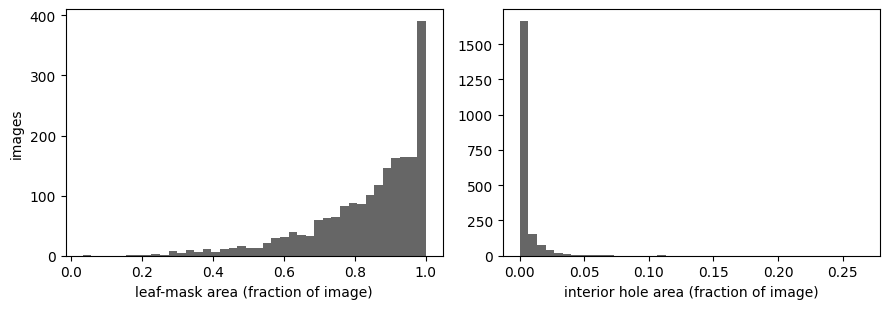


  MASK AUDIT on 2000 random test images
    mean / median leaf area            : 0.836 / 0.885
    mask almost EMPTY (area < 5%)      : 0.1% of images
    mask SMALL (area < 20%)            : 0.1% of images
    mask almost FULL (area > 98%)      : 17.4% of images
    hole inside leaf >= 1% of image    : 12.3% of images   (>= 5%: 1.1%)
    classes with the smallest mean area: Apple___Cedar_apple_ru 0.63, Peach___healthy 0.65, Raspberry___healthy 0.71

PAPER SENTENCE (edit the words, keep the numbers):
  On 2000 random test images the colour-based leaf mask was almost empty for 0.1% and almost complete for 17.4% of images, and 12.3% of masks contained an interior hole of at least 1% of the image area.


In [14]:
# ##############################################################################################
# ####  NEW CODE (CHANGE 3 of 6)  ·  added by Claude  ·  NO TRAINING  ·  about 1 minute    ####
# ##############################################################################################
from scipy import ndimage

MASK_AUDIT_N = 2000                                                    # <<< NEW: number of test images to check

def mask_audit(ctx, n=MASK_AUDIT_N, seed=0):                           # <<< NEW FUNCTION (uses your existing leaf_mask)
    rng = np.random.default_rng(seed)
    ids = np.sort(rng.choice(ctx.idx_test, min(n, len(ctx.idx_test)), replace=False))
    area, hole = [], []
    for i in range(0, len(ids), 256):
        xb = torch.from_numpy(np.ascontiguousarray(ctx.arr[ids[i:i + 256]])).to(ctx.dev)
        m = (leaf_mask(to_float(xb)).cpu().numpy()[:, 0] > 0.5)         # (B,H,W) True = "leaf"
        area.append(m.reshape(len(m), -1).mean(1))
        for mi in m:                                                    # <<< NEW: holes = background blobs that do NOT touch the border
            lab, k = ndimage.label(~mi)
            if k == 0:
                hole.append(0.0)
                continue
            border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
            inner = (lab > 0) & ~np.isin(lab, border)
            hole.append(float(inner.mean()))
    area, hole = np.concatenate(area), np.asarray(hole)
    res = dict(n_images=int(len(ids)), mean_area=float(area.mean()), median_area=float(np.median(area)),
               pct_empty_lt5=float(100 * (area < 0.05).mean()), pct_small_lt20=float(100 * (area < 0.20).mean()),
               pct_full_gt98=float(100 * (area > 0.98).mean()),
               pct_hole_ge1=float(100 * (hole >= 0.01).mean()), pct_hole_ge5=float(100 * (hole >= 0.05).mean()))
    cls = np.array([ctx.classes[j] for j in ctx.y[ids]])
    tab = pd.DataFrame({"image_index": ids, "class": cls, "leaf_area": area, "interior_hole": hole})
    tab.to_csv(ctx.tab_dir / "mask_audit.csv", index=False)
    per = tab.groupby("class").leaf_area.mean().sort_values()
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    ax[0].hist(area, bins=40, color="0.4"); ax[0].set_xlabel("leaf-mask area (fraction of image)"); ax[0].set_ylabel("images")
    ax[1].hist(hole, bins=40, color="0.4"); ax[1].set_xlabel("interior hole area (fraction of image)")
    plt.tight_layout(); plt.savefig(ctx.fig_dir / "fig_mask_audit.png", dpi=200); plt.show()
    log(f"\n  MASK AUDIT on {res['n_images']} random test images")
    log(f"    mean / median leaf area            : {res['mean_area']:.3f} / {res['median_area']:.3f}")
    log(f"    mask almost EMPTY (area < 5%)      : {res['pct_empty_lt5']:.1f}% of images")
    log(f"    mask SMALL (area < 20%)            : {res['pct_small_lt20']:.1f}% of images")
    log(f"    mask almost FULL (area > 98%)      : {res['pct_full_gt98']:.1f}% of images")
    log(f"    hole inside leaf >= 1% of image    : {res['pct_hole_ge1']:.1f}% of images   (>= 5%: {res['pct_hole_ge5']:.1f}%)")
    log(f"    classes with the smallest mean area: " + ", ".join(f"{k[:22]} {v:.2f}" for k, v in per.head(3).items()))
    return res

mask_result = mask_audit(ctx)
print("\nPAPER SENTENCE (edit the words, keep the numbers):")
print(f"  On {mask_result['n_images']} random test images the colour-based leaf mask was almost empty for "
      f"{mask_result['pct_empty_lt5']:.1f}% and almost complete for {mask_result['pct_full_gt98']:.1f}% of images, and "
      f"{mask_result['pct_hole_ge1']:.1f}% of masks contained an interior hole of at least 1% of the image area.")
# ####################################  end of CHANGE 3  ######################################

<div style="background:#fff3cd;border-left:8px solid #ff9800;padding:10px 16px;font-size:15px;color:#222">
<b>NEW CODE &mdash; CHANGE 4 of 6 &middot; Official-split experiment = measure the leakage (ONE short training run)</b><br>
<b>What:</b> trains ONE model (default EfficientNet-B0, seed 0) on the dataset's <b>official</b> train folder and tests it on the official valid folder &mdash; the way most papers do it. Then it splits the official valid images into those that <b>have</b> a training sibling and those that <b>do not</b>, and compares the accuracy of the two groups for the same model.<br><b>Why:</b> this turns &quot;55.17% overlap&quot; into a measured accuracy effect (RQ1). The comparison inside one model is the clean one; the comparison with your group-aware test is shown too, with its caveat.<br><b>Time:</b> about 6 minutes for EfficientNet-B0 (change <code>OFFICIAL_MODEL</code> to <code>mobilenet_v3_small</code> for about 2 minutes). Runs are cached: running the cell again does not retrain.<br><b>Safe:</b> new file names start with <code>OFFICIAL-</code>, so none of your 18 runs is overwritten.
</div>

In [16]:
# ##############################################################################################
# ####  NEW CODE (CHANGE 4 of 6)  ·  added by Claude  ·  ONE short training run (~6 min)   ####
# ##############################################################################################
OFFICIAL_MODEL  = "efficientnet_b0"   # <<< NEW setting: "efficientnet_b0" (~6 min) | "mobilenet_v3_small" (~2 min) | "resnet9" (~9 min)
OFFICIAL_SEED   = 0                   # <<< NEW setting
OFFICIAL_EPOCHS = None                # <<< NEW setting: None = same number of epochs as your main experiment (6)

def train_run_official(ctx, df, name, seed, epochs=None):               # <<< NEW FUNCTION (a copy of your train_run, lines marked "CHANGED" differ)
    a, dev = ctx.args, ctx.dev
    epochs = epochs or a.epochs
    rid = f"OFFICIAL-{name}-std-s{seed}-{ctx.sig}"                       # <<< CHANGED: new name, never overwrites your 18 runs
    jf, ck = ctx.runs_dir / f"{rid}.json", ctx.ckpt_dir / f"{rid}.pt"
    if jf.exists() and ck.exists():
        log(f"  [skip] {rid} (already finished - no retraining)")
        return json.load(open(jf))
    # <<< NEW: the dataset's OWN folders instead of the group-aware split
    off_tr = np.where((df.official.values == "train") & ctx.ok)[0]
    off_va = np.where((df.official.values == "valid") & ctx.ok)[0]
    log(f"\n=== RUN {rid} ===  official train {len(off_tr)} images | official valid {len(off_va)} images")
    seed_everything(seed)
    model, used = build_model(name, ctx.nc, a.width, bool(a.pretrained))
    model = model.to(dev).to(memory_format=torch.channels_last)
    lr = a.lr or (1e-3 if used else 3e-3)
    steps = len(off_tr) // ctx.bs                                        # <<< CHANGED (was len(ctx.idx_train))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=a.wd)
    total = max(4, epochs * steps)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=total,
                                                pct_start=min(0.5, max(0.25, 3.0 / total)))
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=ctx.amp)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=ctx.amp)
    yv = torch.as_tensor(ctx.y[off_va])                                  # <<< CHANGED (was ctx.idx_val)
    hist, best_acc, best_state, t_train = [], -1.0, None, 0.0
    for ep in range(epochs):
        model.train(); t0 = time.time()
        tot = torch.zeros((), device=dev); cor = torch.zeros((), device=dev); n = 0
        for xb, yb in iterate_batches(ctx.arr, ctx.y, off_tr, ctx.bs, dev, shuffle=True,      # <<< CHANGED (was ctx.idx_train)
                                      seed=seed * 1000 + ep, drop_last=True):
            x = gpu_augment(to_float(xb), 0.0)                           # standard augmentation only
            with torch.autocast(device_type=dev.type, dtype=torch.float16 if dev.type == "cuda" else torch.bfloat16,
                                enabled=ctx.amp):
                out = model(x)
                loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.detach() * len(yb); cor += (out.argmax(1) == yb).sum(); n += len(yb)
        t_ep = time.time() - t0; t_train += t_ep
        vl = predict_logits(model, ctx.arr, off_va, dev, ctx.amp)       # <<< CHANGED (was ctx.idx_val)
        v_loss, v_acc = F.cross_entropy(vl, yv).item(), (vl.argmax(1) == yv).float().mean().item()
        hist.append(dict(epoch=ep + 1, train_loss=(tot / n).item(), train_acc=(cor / n).item(), val_loss=v_loss, val_acc=v_acc, sec=t_ep))
        log(f"  ep {ep + 1}/{epochs} | train {hist[-1]['train_loss']:.4f}/{hist[-1]['train_acc']:.4f} | official-valid {v_loss:.4f}/{v_acc:.4f} | {t_ep:.0f}s")
        if v_acc >= best_acc:
            best_acc, best_state = v_acc, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save(best_state, ck)
    # ---- <<< NEW: the leakage measurement ---------------------------------------------------------------
    vl = predict_logits(model, ctx.arr, off_va, dev, ctx.amp)
    correct = (vl.argmax(1).numpy() == ctx.y[off_va])
    sibling = df.group.iloc[off_va].isin(set(df.group.iloc[off_tr])).values       # True = this valid image has a training sibling
    def acc_ci(c):
        lo, hi = bootstrap_ci(c) if len(c) else (float("nan"), float("nan"))
        return dict(acc=float(c.mean()) if len(c) else float("nan"), n=int(len(c)), ci_lo=lo, ci_hi=hi)
    res = dict(run_id=rid, model=name, seed=seed, epochs=epochs, n_train=int(len(off_tr)), n_valid=int(len(off_va)),
               pretrained=bool(used), train_sec=t_train, best_official_val_acc=float(best_acc),
               all_valid=acc_ci(correct), with_sibling=acc_ci(correct[sibling]), without_sibling=acc_ci(correct[~sibling]),
               share_with_sibling=float(sibling.mean()), history=hist)
    jdump(res, jf)
    del model
    if dev.type == "cuda":
        torch.cuda.empty_cache()
    return res

def show_leakage_effect(res, ctx):                                       # <<< NEW FUNCTION
    A, S, N = res["all_valid"], res["with_sibling"], res["without_sibling"]
    pct = lambda d: f"{100 * d['acc']:.2f}%  (n={d['n']:,}, 95% CI {100 * d['ci_lo']:.2f}-{100 * d['ci_hi']:.2f})"
    print("\n" + "=" * 100)
    print(f"LEAKAGE EFFECT  |  {res['model']}, seed {res['seed']}, {res['epochs']} epochs, trained on the OFFICIAL train folder ({res['n_train']:,} images)")
    print("=" * 100)
    print(f"  Official valid, ALL images ............. {pct(A)}")
    print(f"  Official valid, WITH a train sibling ... {pct(S)}   <- the leaky part")
    print(f"  Official valid, WITHOUT a sibling ...... {pct(N)}   <- the clean part")
    gap = 100 * (S["acc"] - N["acc"])
    print(f"  -> inside this one model, siblings add   {gap:+.2f} percentage points")
    f = ctx.tab_dir / "all_runs_raw.csv"
    ga = None
    if f.exists():
        raw = pd.read_csv(f)
        row = raw[(raw.model == res["model"]) & (raw.aug == "std") & (raw.seed == res["seed"])]
        if len(row):
            ga = row.iloc[0]
            print(f"  Group-aware split (your main experiment), same model & seed: test acc {100 * ga.test_acc:.2f}%, val acc {100 * ga.val_acc:.2f}%")
            print(f"  -> official-valid minus group-aware-test = {100 * (A['acc'] - ga.test_acc):+.2f} points")
            print("     (caveat: different image sets and 12% more training images, so use the 'with vs without sibling' gap as the main evidence)")
    pd.DataFrame([dict(setting="official valid (all)", **A), dict(setting="official valid, with sibling", **S),
                  dict(setting="official valid, without sibling", **N)]).to_csv(ctx.tab_dir / "leakage_effect.csv", index=False)
    print("\nPAPER SENTENCE (edit the words, keep the numbers):")
    print(f"  Training {res['model']} on the official folders gave {100 * A['acc']:.2f}% on the official validation folder"
          + (f", against {100 * ga.test_acc:.2f}% on the group-aware test split" if ga is not None else "")
          + f". Within the official validation folder, images with a training sibling were classified with {100 * S['acc']:.2f}% accuracy"
          f" (n = {S['n']:,}) against {100 * N['acc']:.2f}% (n = {N['n']:,}) for images without one.")

official_result = train_run_official(ctx, df_all, OFFICIAL_MODEL, OFFICIAL_SEED, OFFICIAL_EPOCHS)
show_leakage_effect(official_result, ctx)
# ####################################  end of CHANGE 4  ######################################


=== RUN OFFICIAL-efficientnet_b0-std-s0-dfbadede ===  official train 70295 images | official valid 17572 images
  ep 1/6 | train 0.9545/0.7897 | official-valid 0.1339/0.9601 | 55s
  ep 2/6 | train 0.1003/0.9689 | official-valid 0.0887/0.9741 | 55s
  ep 3/6 | train 0.0491/0.9847 | official-valid 0.0307/0.9904 | 58s
  ep 4/6 | train 0.0246/0.9920 | official-valid 0.0120/0.9960 | 55s
  ep 5/6 | train 0.0087/0.9972 | official-valid 0.0069/0.9983 | 54s
  ep 6/6 | train 0.0050/0.9984 | official-valid 0.0062/0.9983 | 54s

LEAKAGE EFFECT  |  efficientnet_b0, seed 0, 6 epochs, trained on the OFFICIAL train folder (70,295 images)
  Official valid, ALL images ............. 99.83%  (n=17,572, 95% CI 99.77-99.89)
  Official valid, WITH a train sibling ... 99.90%  (n=9,694, 95% CI 99.83-99.96)   <- the leaky part
  Official valid, WITHOUT a sibling ...... 99.76%  (n=7,878, 95% CI 99.66-99.86)   <- the clean part
  -> inside this one model, siblings add   +0.14 percentage points
  Group-aware split 

<div style="background:#fff3cd;border-left:8px solid #ff9800;padding:10px 16px;font-size:15px;color:#222">
<b>NEW CODE &mdash; CHANGE 5 of 6 &middot; OPTIONAL: background-augmentation ablation (ONE training run, ~9 minutes)</b><br>
<b>What:</b> trains ResNet-9+SE with background augmentation at a LOWER probability (default 0.1 instead of 0.5) and evaluates it with your existing evaluation code.<br><b>Why:</b> if the collapse on the field shift shrinks when the augmentation is gentler, that supports the &quot;augmentation hurts&quot; explanation; if not, the cause is elsewhere. Either result is useful for the Discussion.<br><b>Skip this cell</b> if you are short of time: the paper is complete without it.<br><b>Safe:</b> uses a different run signature, so your original 18 runs are untouched.
</div>

In [17]:
# ##############################################################################################
# ####  NEW CODE (CHANGE 5 of 6)  ·  added by Claude  ·  OPTIONAL  ·  ONE run (~9 min)     ####
# ##############################################################################################
BG_ABLATION_P = [0.1]        # <<< NEW setting: probabilities to try (each value = one ~9 minute run)
BG_ABLATION_SEED = 0         # <<< NEW setting

def run_bg_ablation(ctx, ps=BG_ABLATION_P, seed=BG_ABLATION_SEED):      # <<< NEW FUNCTION (calls your existing train_run unchanged)
    rows = []
    f = ctx.tab_dir / "all_runs_raw.csv"
    cols = ["test_acc", "probe_field_sim", "probe_leaf_on_random_bg", "probe_blur", "probe_noise"]
    if f.exists():
        raw = pd.read_csv(f)
        for aug, label in (("std", "no BG-aug (p=0)"), ("bg", "BG-aug p=0.5 (your original)")):
            r = raw[(raw.model == "resnet9_se") & (raw.aug == aug) & (raw.seed == seed)]
            if len(r):
                rows.append(dict(setting=label, **{c: float(r.iloc[0][c]) for c in cols}))
    for p in ps:
        a2 = copy.copy(ctx.args); a2.bg_prob = p                         # <<< NEW: only the probability changes
        ctx_p = copy.copy(ctx); ctx_p.args = a2; ctx_p.sig = run_sig(a2) # <<< NEW: different signature = different files
        m = train_run(ctx_p, "resnet9_se", "bg", seed)
        rows.append(dict(setting=f"BG-aug p={p} (NEW)", **{c: float(m[c]) for c in cols}))
    out = pd.DataFrame(rows)
    out.to_csv(ctx.tab_dir / "bg_ablation.csv", index=False)
    return out

bg_result = run_bg_ablation(ctx)
show = bg_result.copy()
for c in show.columns[1:]:
    show[c] = (100 * show[c]).round(1)
print("\nBACKGROUND-AUGMENTATION ABLATION  (ResNet-9+SE, seed %d; accuracies in %%)" % BG_ABLATION_SEED)
print(show.to_string(index=False))
# ####################################  end of CHANGE 5  ######################################


=== RUN resnet9_se-bg-s0-49855042 ===
  ep 1/6 | train 1.6356/0.5506 | val 1.0603/0.6996 | 81s
  ep 2/6 | train 0.5146/0.8390 | val 0.6668/0.7983 | 79s
  ep 3/6 | train 0.2808/0.9097 | val 0.3824/0.8961 | 79s
  ep 4/6 | train 0.1527/0.9498 | val 0.1987/0.9360 | 79s
  ep 5/6 | train 0.0772/0.9745 | val 0.0855/0.9703 | 79s
  ep 6/6 | train 0.0406/0.9869 | val 0.0674/0.9782 | 79s
  -> test acc 0.9740 | macro-F1 0.9739 | held-out field-sim acc 0.3850

BACKGROUND-AUGMENTATION ABLATION  (ResNet-9+SE, seed 0; accuracies in %)
                     setting  test_acc  probe_field_sim  probe_leaf_on_random_bg  probe_blur  probe_noise
             no BG-aug (p=0)      97.6             52.2                     64.1        22.0         28.8
BG-aug p=0.5 (your original)      96.1             16.4                     95.3        14.0          9.0
          BG-aug p=0.1 (NEW)      97.4             38.5                     96.6        14.3         12.8


<div style="background:#e3f2fd;border-left:8px solid #1565c0;padding:10px 16px;font-size:15px;color:#222">
<b>NEW CODE &mdash; CHANGE 6 of 6 &middot; One block to paste back to Claude (NO training, seconds)</b><br>
<b>What:</b> collects the results of CHANGES 2, 3, 4 and 5 into one JSON block, saves it, and copies the new files to your Google Drive folder.<br><b>What to do:</b> select everything printed between the two lines of equal signs and paste it into the chat. That is all I need to update the paper.
</div>

In [18]:
# ##############################################################################################
# ####  NEW CODE (CHANGE 6 of 6)  ·  added by Claude  ·  NO TRAINING  ·  seconds           ####
# ##############################################################################################
def _g(name):
    return globals().get(name)

summary = dict(
    leakage_effect=_g("official_result"),
    mask_audit=_g("mask_result"),
    bg_ablation=(_g("bg_result").to_dict("records") if _g("bg_result") is not None else None),
    latency_median=(_g("lat_summary").reset_index().to_dict("records") if _g("lat_summary") is not None else None),
    hardware=_g("hw"),
)
if summary["leakage_effect"]:
    summary["leakage_effect"] = {k: v for k, v in summary["leakage_effect"].items() if k != "history"}   # keep the block short
jdump(summary, ctx.out_dir / "summary_for_paper.json")

print("=" * 90 + "\nCOPY EVERYTHING BETWEEN THESE LINES AND PASTE IT TO CLAUDE\n" + "=" * 90)
print(json.dumps(json.loads(json.dumps(summary, default=lambda o: o.item() if hasattr(o, "item") else str(o))), indent=1))
print("=" * 90)

# optional: copy the new files to Drive (same folder you used before)
try:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    shutil.copytree(str(ctx.out_dir), "/content/drive/MyDrive/plant_project_outputs", dirs_exist_ok=True)
    print("copied to Google Drive: plant_project_outputs")
except Exception as e:
    print("(Drive copy skipped:", type(e).__name__, ")")
# ####################################  end of CHANGE 6  ######################################

COPY EVERYTHING BETWEEN THESE LINES AND PASTE IT TO CLAUDE
{
 "leakage_effect": {
  "run_id": "OFFICIAL-efficientnet_b0-std-s0-dfbadede",
  "model": "efficientnet_b0",
  "seed": 0,
  "epochs": 6,
  "n_train": 70295,
  "n_valid": 17572,
  "pretrained": true,
  "train_sec": 331.4357576370239,
  "best_official_val_acc": 0.998349666595459,
  "all_valid": {
   "acc": 0.9983496471659459,
   "n": 17572,
   "ci_lo": 0.9976667425449579,
   "ci_hi": 0.9989187343501025
  },
  "with_sibling": {
   "acc": 0.9989684340829379,
   "n": 9694,
   "ci_lo": 0.9983494945327006,
   "ci_hi": 0.9995873736331752
  },
  "without_sibling": {
   "acc": 0.9975882203604975,
   "n": 7878,
   "ci_lo": 0.9965727341964966,
   "ci_hi": 0.9986037065244986
  },
  "share_with_sibling": 0.5516731163214205
 },
 "mask_audit": {
  "n_images": 2000,
  "mean_area": 0.8364393005371094,
  "median_area": 0.88482666015625,
  "pct_empty_lt5": 0.05,
  "pct_small_lt20": 0.15,
  "pct_full_gt98": 17.45,
  "pct_hole_ge1": 12.3,
  "pct_hol

<div style="background:#eeeeee;border-left:8px solid #616161;padding:10px 16px;font-size:15px;color:#222">
<b>ORIGINAL LATER CELLS &mdash; unchanged (kept so nothing is lost). You do NOT need to run any of them again.</b><br>
Warning: the cell that prints "hello world" is an endless keep-alive loop. Never use "Run all" on this notebook.
</div>

In [ ]:
!du -sh /content/outputs/* | sort -h

In [ ]:
from google.colab import drive
import shutil
drive.mount('/content/drive')
shutil.copytree('/content/outputs', '/content/drive/MyDrive/plant_project_outputs', dirs_exist_ok=True)
print("done")

In [ ]:
!pip -q install lime scikit-image

from lime import lime_image
from skimage.segmentation import mark_boundaries
print("LIME installed correctly")

In [ ]:
# Install LIME automatically if missing
import sys, subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "lime", "scikit-image"
])

from lime import lime_image
from skimage.segmentation import mark_boundaries

print("LIME is available")

In [ ]:
import sys
import subprocess
from pathlib import Path

# Install LIME if needed
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "lime"
])

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from lime import lime_image


def lime_figure(ctx, wrap, path, n=3):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    wrap.eval()

    def predict(images):
        x = torch.from_numpy(
            np.asarray(images, dtype=np.float32)
        ).permute(0, 3, 1, 2).to(ctx.dev)

        with torch.no_grad():
            return F.softmax(wrap(x), dim=1).cpu().numpy()

    ids = ctx.idx_test[
        np.linspace(0, len(ctx.idx_test) - 1, n).astype(int)
    ]

    explainer = lime_image.LimeImageExplainer(random_state=0)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))

    if n == 1:
        axes = np.asarray(axes).reshape(2, 1)

    for col, image_id in enumerate(ids):
        image = np.asarray(ctx.arr[image_id], dtype=np.float32) / 255.0

        explanation = explainer.explain_instance(
            image,
            predict,
            top_labels=1,
            hide_color=0,
            num_samples=300,
            batch_size=32
        )

        label = explanation.top_labels[0]
        _, mask = explanation.get_image_and_mask(
            label,
            positive_only=True,
            num_features=8,
            hide_rest=False
        )

        axes[0, col].imshow(image)
        axes[0, col].axis("off")
        axes[0, col].set_title("Original")

        axes[1, col].imshow(image)
        axes[1, col].imshow(
            np.ma.masked_where(mask == 0, mask),
            cmap="Reds",
            alpha=0.55
        )
        axes[1, col].axis("off")
        axes[1, col].set_title(f"LIME: {ctx.classes[label][:20]}")

    plt.tight_layout()
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)

    print(f"LIME image saved to: {path}")


# Re-run reporting using the saved checkpoints
main(["--lime", "--export", "0"])

lime_path = Path("/content/outputs/figures/fig_lime.png")

if not lime_path.exists():
    raise FileNotFoundError(f"LIME image was not created: {lime_path}")

from IPython.display import display, Image
display(Image(filename=str(lime_path)))

In [ ]:
from google.colab import drive
import shutil
from pathlib import Path

drive.mount("/content/drive", force_remount=True)

src = Path("/content/outputs/figures/fig_lime.png")
dst_dir = Path("/content/drive/MyDrive/plant_project_outputs")
dst_dir.mkdir(parents=True, exist_ok=True)

if not src.exists():
    raise FileNotFoundError(f"Missing file: {src}")

shutil.copy2(src, dst_dir / src.name)
print(f"Copied to: {dst_dir / src.name}")

In [ ]:
import glob, numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

root = find_pv_root(None)
df, classes = index_pv(root)
tr, va, te = make_split(df, 42)                       # identical split to the experiment (split_seed 42)
arr = np.load([f for f in glob.glob("/content/cache/pv_128_*.npy") if not f.endswith(".ok.npy")][0], mmap_mode="r")

CK, SIG = "/content/outputs/ckpt/", "dfbadede"        # SIG = run signature in your checkpoint file names
MODELS = {                                            # label : (model name, checkpoint file)
    "EfficientNet-B0":    ("efficientnet_b0", f"efficientnet_b0-std-s0-{SIG}.pt"),
    "ResNet-9":           ("resnet9",         f"resnet9-std-s0-{SIG}.pt"),
    "ResNet-9+SE+BG-aug": ("resnet9_se",      f"resnet9_se-bg-s0-{SIG}.pt"),
}
loaded = {}
for label, (nm, fn) in MODELS.items():
    m, _ = build_model(nm, len(classes), 32, False)
    m.load_state_dict(torch.load(CK + fn, map_location="cpu"))
    loaded[label] = (m.to(dev).eval(), nm)
print("loaded:", list(loaded), "| test images:", len(te))

In [ ]:
def get_batch(ids):
    ids = np.sort(np.asarray(ids))
    return to_float(torch.from_numpy(np.ascontiguousarray(arr[ids])).to(dev)), ids

def di_trace(model, x, cam, target, grid=8, steps=8):
    """Same procedure as the pipeline's deletion_insertion(), but it also returns the probabilities and images of every step."""
    B, _, H, W = x.shape
    rank = F.adaptive_avg_pool2d(cam[:, None], grid).flatten(1).argsort(1, descending=True).argsort(1)
    k = odd(H / 4)
    base = F.avg_pool2d(x, k, 1, k // 2, count_include_pad=False)       # blurred image = "removed" content
    p_del, p_ins, im_del, im_ins = [], [], [], []
    with torch.no_grad():
        for s in range(steps + 1):
            n = int(round(s / steps * grid * grid))
            M = F.interpolate((rank < n).float().view(B, 1, grid, grid), size=(H, W), mode="nearest")
            xd, xi = x * (1 - M) + base * M, base * (1 - M) + x * M
            p_del.append(F.softmax(model(xd), 1).gather(1, target[:, None])[:, 0])
            p_ins.append(F.softmax(model(xi), 1).gather(1, target[:, None])[:, 0])
            im_del.append(xd.cpu()); im_ins.append(xi.cpu())
    return torch.stack(p_del, 1).cpu(), torch.stack(p_ins, 1).cpu(), im_del, im_ins

ex_ids = te[np.linspace(0, len(te) - 1, 8).astype(int)]               # 8 fixed example test images

def fig_di_example(label, j=0, steps=8, show=(0, 1, 2, 4, 6, 8), save=None):
    """Row 1: input + Grad-CAM. Row 2: deletion strip. Row 3: insertion strip (j = which of the 8 example images)."""
    model, nm = loaded[label]
    x, ids = get_batch(ex_ids[j:j + 1])
    cam, pred, _ = gradcam(model, x, cam_layer(model, nm))
    p_del, p_ins, im_del, im_ins = di_trace(model, x, cam, pred, steps=steps)
    img = x[0].permute(1, 2, 0).cpu().numpy()
    nc = len(show) + 1
    fig, ax = plt.subplots(3, nc, figsize=(2.1 * nc, 6.9))
    ax[0, 0].imshow(img); ax[0, 0].set_title("input\ntrue: " + classes[int(df.label.values[ids[0]])][:24], fontsize=7)
    ax[0, 1].imshow(img); ax[0, 1].imshow(cam[0].cpu().numpy(), cmap="jet", alpha=0.45)
    ax[0, 1].set_title(f"Grad-CAM ({label})\npred: " + classes[int(pred)][:24], fontsize=7)
    for r, (ims, pr, name, verb) in enumerate([(im_del, p_del, "DELETION", "removed"), (im_ins, p_ins, "INSERTION", "revealed")], start=1):
        ax[r, 0].text(0.5, 0.5, f"{name}\nmost salient patches\n{verb} first", ha="center", va="center", fontsize=8)
        for c, s in enumerate(show):
            ax[r, c + 1].imshow(ims[s][0].permute(1, 2, 0).clamp(0, 1).numpy())
            ax[r, c + 1].set_title(f"{100 * s / steps:.0f}% {verb}\np = {pr[0, s]:.2f}", fontsize=7)
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=300)
    plt.show()

def fig_di_curves(n=200, steps=8, chunk=25, save=None):
    """Mean probability of the predicted class vs fraction of patches removed / revealed, one line per model.
    n=200 reproduces the images behind the AUCs in table4_explainability."""
    sel = np.sort(np.random.default_rng(0).choice(te, min(n, len(te)), replace=False))
    xs = np.arange(steps + 1) / steps * 100
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for label, (model, nm) in loaded.items():
        Pd, Pi = [], []
        for i in range(0, len(sel), chunk):
            x, _ = get_batch(sel[i:i + chunk])
            cam, pred, _ = gradcam(model, x, cam_layer(model, nm))
            pdl, pil, _, _ = di_trace(model, x, cam, pred, steps=steps)
            Pd.append(pdl); Pi.append(pil)
        Pd, Pi = torch.cat(Pd).numpy(), torch.cat(Pi).numpy()
        auc = lambda P: (((P[:, 1:] + P[:, :-1]) / 2).sum(1) / steps).mean()
        ax[0].plot(xs, Pd.mean(0), marker="o", label=f"{label} (AUC {auc(Pd):.3f})")
        ax[1].plot(xs, Pi.mean(0), marker="o", label=f"{label} (AUC {auc(Pi):.3f})")
    ax[0].set_title("Deletion (lower AUC = better)"); ax[0].set_xlabel("% of most-salient patches removed")
    ax[1].set_title("Insertion (higher AUC = better)"); ax[1].set_xlabel("% of most-salient patches revealed")
    for a in ax:
        a.set_ylabel("probability of predicted class"); a.grid(alpha=0.3); a.legend(fontsize=7)
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=300)
    plt.show()

import os; os.makedirs("/content/outputs/figures", exist_ok=True)
for label in loaded:
    fig_di_example(label, j=0, save=f"/content/outputs/figures/di_example_{label.replace(' ', '_').replace('+', '')}.png")
fig_di_curves(n=200, save="/content/outputs/figures/di_curves.png")

In [ ]:
import numpy as np
from PIL import Image

def pointing_game_score(cam, mask):
    """
    cam: 2D Grad-CAM array, shape (H, W)
    mask: 2D lesion mask, nonzero where lesion exists
    """
    mask = np.asarray(mask) > 0

    if not mask.any():
        return np.nan

    max_y, max_x = np.unravel_index(np.argmax(cam), cam.shape)
    return float(mask[max_y, max_x])


def evaluate_pointing_game(model, images, lesion_masks, device):
    scores = []

    for image, mask in zip(images, lesion_masks):
        cam, _, _ = gradcam(model, image.to(device), cam_layer(model, "resnet9_se"))
        cam = cam[0].detach().cpu().numpy()

        mask = np.asarray(mask.resize((cam.shape[1], cam.shape[0]))) > 0
        scores.append(pointing_game_score(cam, mask))

    scores = np.asarray(scores)
    scores = scores[~np.isnan(scores)]

    return float(scores.mean()), scores

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch

mask_dir = Path("/content/lesion_masks")
print("Mask folder:", mask_dir)
print("Folder exists:", mask_dir.exists())

if not mask_dir.exists():
    print("No lesion masks found. Create/upload masks first.")
else:
    mask_files = list(mask_dir.glob("*.png"))
    print("Masks found:", len(mask_files))

    if len(mask_files) == 0:
        print("No .png masks found; Pointing Game score cannot be calculated.")
    else:
        # Use the already-loaded model and test images
        model.eval()
        test_ids = te[:min(20, len(te))]
        layer = cam_layer(model, "resnet9_se")

        hits = []
        checked = 0

        for image_id in test_ids:
            mask_path = mask_dir / f"{int(image_id)}.png"

            if not mask_path.exists():
                print("Missing mask:", mask_path.name)
                continue

            image = np.asarray(arr[image_id], dtype=np.float32) / 255.0
            x = torch.from_numpy(image).permute(2, 0, 1)[None].to(dev)

            cam, _, _ = gradcam(model, x, layer)
            cam = cam[0].detach().cpu().numpy()

            mask = Image.open(mask_path).convert("L")
            mask = mask.resize(
                (cam.shape[1], cam.shape[0]),
                Image.Resampling.NEAREST
            )
            mask = np.asarray(mask) > 0

            peak_y, peak_x = np.unravel_index(np.argmax(cam), cam.shape)
            hit = bool(mask[peak_y, peak_x])

            hits.append(hit)
            checked += 1
            print(
                f"{mask_path.name}: "
                f"{'HIT' if hit else 'MISS'} "
                f"(peak={peak_x},{peak_y})"
            )

        if checked == 0:
            print("No matching image/mask pairs were found.")
        else:
            score = np.mean(hits)
            print(f"\nPointing Game score: {score:.4f}")
            print(f"Pointing Game percentage: {score * 100:.2f}%")
            print(f"Images evaluated: {checked}")

In [ ]:
import pandas as pd

runs = pd.read_csv("/content/outputs/tables/all_runs_raw.csv")

runs["accuracy_drop_pp"] = (
    runs["probe_clean"] - runs["probe_field_sim"]
) * 100

print(runs[[
    "model", "aug", "seed",
    "probe_clean", "probe_field_sim",
    "accuracy_drop_pp"
]].to_string(index=False))

In [ ]:
from google.colab import drive
import shutil
drive.mount('/content/drive')
shutil.copytree('/content/outputs', '/content/drive/MyDrive/plant_project_outputs', dirs_exist_ok=True)
print("done")